# Implementasi dan Optimasi Support Vector Machine (SVM) dengan Pembanding K-Nearest Neighbors (KNN) pada Klasifikasi Penyakit Jantung

**Referensi Utama:**
- Rahmat Hidayat et al. (2024), *Implementasi Machine Learning Untuk Prediksi Penyakit Jantung Menggunakan Algoritma Support Vector Machine*, BIOS: Jurnal Teknologi Informasi dan Rekayasa Komputer, Vol. 5, No. 2, hlm. 161-168, DOI: `10.37148/bios.v5i2.152`.
- Dataset: `data/heart.csv` (Kaggle Heart Disease Dataset, 1.025 baris mentah, 14 kolom).

**Fokus Eksperimen:**
1. Replikasi baseline SVM linear sesuai metodologi paper referensi.
2. Audit integritas dataset (duplikasi identik, *duplicate data leakage*, dan anomali kode klinis).
3. Optimasi *pipeline* SVM sebagai model utama (pembersihan anomali, *selective encoding*, *robust scaling*, rekayasa fitur klinis, serta *hyperparameter tuning*).
4. Evaluasi KNN sebagai model pembanding sekunder berbasis ketetanggaan, disertai validasi objektif *Nested Cross-Validation*, uji signifikansi statistik, kalibrasi, *learning curve*, dan *error analysis*.

## 1. Setup & Environment

Konfigurasi lingkungan eksekusi, pustaka ilmiah, konstanta reproduktibilitas, pengelompokan fitur klinis, serta skema *cross-validation* standar yang digunakan di seluruh eksperimen.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
PAPER_RANDOM_STATE = 0
PAPER_TEST_SIZE = 0.2

CV_REPEATED = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=RANDOM_STATE)
CV_OUTER = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
CV_INNER = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CONTINUOUS_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
ORDINAL_COLS = ["ca"]
NOMINAL_COLS = ["cp", "restecg", "slope", "thal"]
BINARY_COLS = ["sex", "fbs", "exang"]

PALETTE = {
    "navy": "#1f4e79",
    "green": "#2e8b57",
    "red": "#c0392b",
    "amber": "#d97706",
    "gray": "#6b7280",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"Seaborn      : {sns.__version__}")

Python       : 3.12.10
NumPy        : 2.0.2
Pandas       : 2.3.3
Scikit-learn : 1.6.1
Matplotlib   : 3.11.2
Seaborn      : 0.13.2


## 2. Data Ingestion & Loading

Pemuatan dataset `heart.csv` dengan *path resolver* lintas direktori kerja serta verifikasi skema, tipe data, nilai kosong, dan deskripsi variabel sesuai Tabel 1 pada paper referensi.

In [2]:
def resolve_dataset_path(filename: str = "heart.csv") -> Path:
    candidates = [
        Path("../data") / filename,
        Path("data") / filename,
        Path(filename),
    ]
    for path in candidates:
        if path.is_file():
            return path.resolve()
    raise FileNotFoundError(f"Dataset {filename} tidak ditemukan pada lokasi standar.")


DATA_PATH = resolve_dataset_path()
df_raw = pd.read_csv(DATA_PATH)

print(f"Lokasi dataset   : {DATA_PATH}")
print(f"Dimensi mentah   : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
print(f"Total missing    : {int(df_raw.isna().sum().sum())}")
print(f"Distribusi target: {df_raw['target'].value_counts().sort_index().to_dict()}")

display(df_raw.head())

Lokasi dataset   : C:\Users\akilm\Projects\uas-data-mining\data\heart.csv
Dimensi mentah   : 1025 baris x 14 kolom
Total missing    : 0
Distribusi target: {0: 499, 1: 526}
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal  target
0   52    1   0       125   212    0        1      168      0      1.0      2   2     3       0
1   53    1   0       140   203    1        0      155      1      3.1      0   0     3       0
2   70    1   0       145   174    0        1      125      1      2.6      0   0     3       0
3   61    1   0       148   203    0        1      161      0      0.0      2   1     3       0
4   62    0   0       138   294    1        1      106      0      1.9      1   3     2       0


In [3]:
FEATURE_DOCS = [
    ("age", "Numerik (Kontinu)", "Usia pasien dalam tahun"),
    ("sex", "Biner (0/1)", "Jenis kelamin (1 = laki-laki, 0 = perempuan)"),
    ("cp", "Kategorikal Nominal (0-3)", "Tipe nyeri dada (4 kategori)"),
    ("trestbps", "Numerik (Kontinu)", "Tekanan darah saat istirahat (mm Hg)"),
    ("chol", "Numerik (Kontinu)", "Kolesterol serum (mg/dl)"),
    ("fbs", "Biner (0/1)", "Gula darah puasa > 120 mg/dl (1 = ya, 0 = tidak)"),
    ("restecg", "Kategorikal Nominal (0-2)", "Hasil elektrokardiografi istirahat"),
    ("thalach", "Numerik (Kontinu)", "Denyut jantung maksimum tercapai (bpm)"),
    ("exang", "Biner (0/1)", "Angina yang diinduksi olahraga (1 = ya, 0 = tidak)"),
    ("oldpeak", "Numerik (Kontinu)", "Depresi segmen ST relatif terhadap istirahat"),
    ("slope", "Kategorikal Nominal (0-2)", "Kemiringan segmen ST puncak saat latihan"),
    ("ca", "Kategorikal Ordinal (0-3, anomali 4)", "Jumlah pembuluh darah utama terwarnai fluoroskopi"),
    ("thal", "Kategorikal Nominal (1-3, anomali 0)", "Status thalassemia / perfusi jantung"),
    ("target", "Target Biner (0/1)", "Label kelas pada dataset (0 vs 1)"),
]

schema_rows = []
for col, scale, desc in FEATURE_DOCS:
    uniq = sorted(df_raw[col].unique().tolist())
    obs_str = (
        f"min={df_raw[col].min()}, max={df_raw[col].max()} ({len(uniq)} unik)"
        if len(uniq) > 8
        else str(uniq)
    )
    schema_rows.append({
        "Kolom": col,
        "Tipe Data": str(df_raw[col].dtype),
        "Skala / Peran": scale,
        "Nilai Teramati": obs_str,
        "Deskripsi Klinis": desc,
    })

schema_df = pd.DataFrame(schema_rows)
display(schema_df)

       Kolom Tipe Data                         Skala / Peran               Nilai Teramati                                   Deskripsi Klinis
0        age     int64                     Numerik (Kontinu)     min=29, max=77 (41 unik)                            Usia pasien dalam tahun
1        sex     int64                           Biner (0/1)                       [0, 1]       Jenis kelamin (1 = laki-laki, 0 = perempuan)
2         cp     int64             Kategorikal Nominal (0-3)                 [0, 1, 2, 3]                       Tipe nyeri dada (4 kategori)
3   trestbps     int64                     Numerik (Kontinu)    min=94, max=200 (49 unik)               Tekanan darah saat istirahat (mm Hg)
4       chol     int64                     Numerik (Kontinu)  min=126, max=564 (152 unik)                           Kolesterol serum (mg/dl)
5        fbs     int64                           Biner (0/1)                       [0, 1]   Gula darah puasa > 120 mg/dl (1 = ya, 0 = tidak)
6    restecg 

## 3. Exploratory Data Analysis (EDA)

### 3.1 Audit Integritas Data dan Duplikasi

Pemeriksaan apakah seluruh 1.025 baris pada `heart.csv` merepresentasikan pasien independen atau mengandung pengulangan identik yang berisiko memicu *duplicate data leakage* saat evaluasi.

Total baris mentah        : 1025
Baris duplikat identik    : 723 (70.54%)
Pasien unik (deduplikasi) : 302 (29.46%)
Konflik label fitur sama  : 0
Multiplisitas per pasien  : {3: 187, 4: 114, 8: 1}
Target mentah             : {0: 499, 1: 526}
Target bersih (302 unik)  : {0: 138, 1: 164}


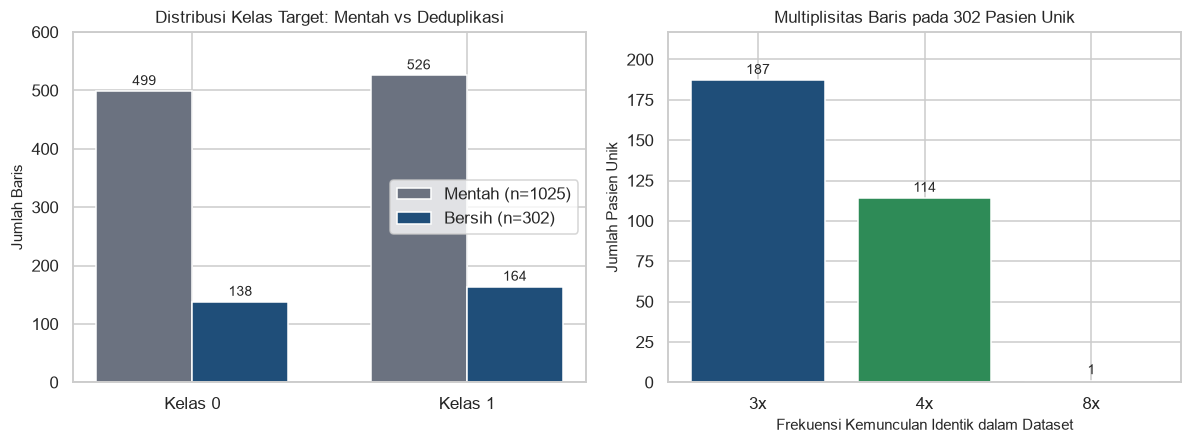

In [4]:
n_total = len(df_raw)
n_dup_exact = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
n_unique = len(df_clean)

feature_cols = [c for c in df_raw.columns if c != "target"]
label_conflicts = int((df_raw.groupby(feature_cols)["target"].nunique() > 1).sum())
multiplicity = df_raw.groupby(df_raw.columns.tolist()).size().value_counts().sort_index()

print(f"Total baris mentah        : {n_total}")
print(f"Baris duplikat identik    : {n_dup_exact} ({n_dup_exact / n_total:.2%})")
print(f"Pasien unik (deduplikasi) : {n_unique} ({n_unique / n_total:.2%})")
print(f"Konflik label fitur sama  : {label_conflicts}")
print(f"Multiplisitas per pasien  : {multiplicity.to_dict()}")
print(f"Target mentah             : {df_raw['target'].value_counts().sort_index().to_dict()}")
print(f"Target bersih (302 unik)  : {df_clean['target'].value_counts().sort_index().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

raw_counts = df_raw["target"].value_counts().sort_index()
clean_counts = df_clean["target"].value_counts().sort_index()
x_pos = np.arange(2)
width = 0.35

b1 = axes[0].bar(x_pos - width / 2, raw_counts.values, width, label="Mentah (n=1025)", color=PALETTE["gray"])
b2 = axes[0].bar(x_pos + width / 2, clean_counts.values, width, label="Bersih (n=302)", color=PALETTE["navy"])
for bar in list(b1) + list(b2):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 10, f"{int(h)}", ha="center", fontsize=9)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["Kelas 0", "Kelas 1"])
axes[0].set_ylim(0, 600)
axes[0].set_ylabel("Jumlah Baris")
axes[0].set_title("Distribusi Kelas Target: Mentah vs Deduplikasi")
axes[0].legend()

mult_labels = [f"{k}x" for k in multiplicity.index]
bars_m = axes[1].bar(mult_labels, multiplicity.values, color=[PALETTE["navy"], PALETTE["green"], PALETTE["amber"]])
for bar in bars_m:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 4, f"{int(h)}", ha="center", fontsize=9)
axes[1].set_ylim(0, max(multiplicity.values) + 30)
axes[1].set_xlabel("Frekuensi Kemunculan Identik dalam Dataset")
axes[1].set_ylabel("Jumlah Pasien Unik")
axes[1].set_title("Multiplisitas Baris pada 302 Pasien Unik")

plt.tight_layout()
plt.show()

**Temuan Audit Duplikasi:** Dari 1.025 baris, sebanyak 723 baris (70,54%) adalah duplikat identik dan hanya terdapat **302 pasien unik** (187 muncul 3x, 114 muncul 4x, dan 1 muncul 8x) dengan nol konflik label. Setelah deduplikasi, proporsi kelas tetap seimbang (138 kelas 0 atau 45,70% vs 164 kelas 1 atau 54,30%). Evaluasi generalisasi yang jujur harus dilakukan pada 302 pasien unik agar model tidak diuji pada data latih yang bocor.

### 3.2 Audit Anomali Kode Klinis dan Hubungan Fitur Kategorikal terhadap Target

Analisis proporsi kelas `target = 1` pada setiap kategori fitur diskret/kategorikal pada 302 pasien unik untuk mendeteksi kode anomali UCI Cleveland serta menentukan skema *encoding* yang tepat (ordinal vs nominal).

Anomali ca == 4   : 4 pasien unik (18 baris mentah)
Anomali thal == 0 : 2 pasien unik (7 baris mentah)
      Fitur  Nilai  Jumlah Pasien  Proporsi Target=1
0        cp      0            143             0.2727
1        cp      1             50             0.8200
2        cp      2             86             0.7907
3        cp      3             23             0.6957
4        ca      0            175             0.7429
5        ca      1             65             0.3231
6        ca      2             38             0.1842
7        ca      3             20             0.1500
8        ca      4              4             0.7500
9      thal      0              2             0.5000
10     thal      1             18             0.3333
11     thal      2            165             0.7818
12     thal      3            117             0.2393
13    slope      0             21             0.4286
14    slope      1            140             0.3500
15    slope      2            141             0.7

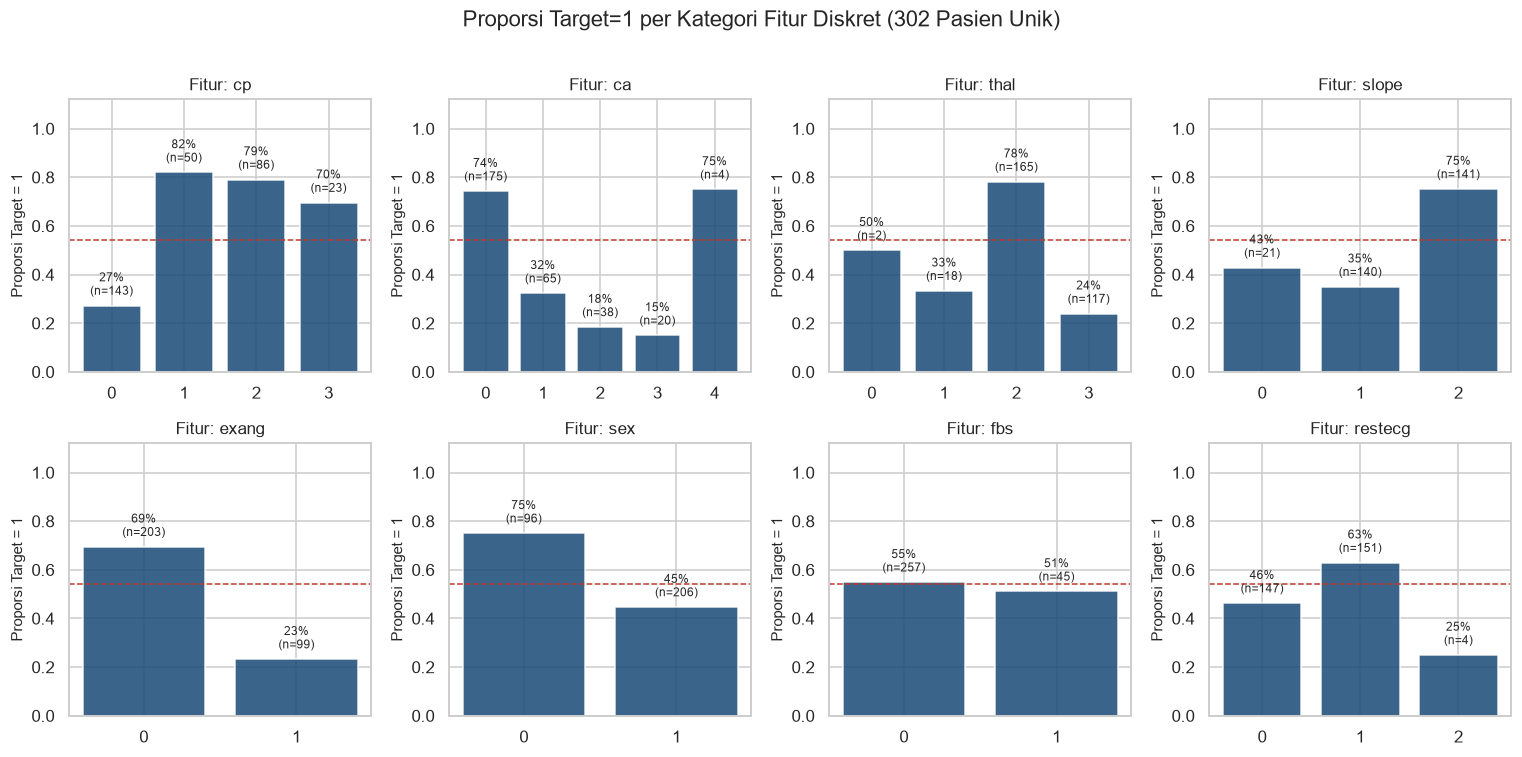

In [5]:
anom_ca_clean = int((df_clean["ca"] == 4).sum())
anom_ca_raw = int((df_raw["ca"] == 4).sum())
anom_thal_clean = int((df_clean["thal"] == 0).sum())
anom_thal_raw = int((df_raw["thal"] == 0).sum())

print(f"Anomali ca == 4   : {anom_ca_clean} pasien unik ({anom_ca_raw} baris mentah)")
print(f"Anomali thal == 0 : {anom_thal_clean} pasien unik ({anom_thal_raw} baris mentah)")

cat_summary_rows = []
cat_check_cols = ["cp", "ca", "thal", "slope", "exang", "sex", "fbs", "restecg"]
for col in cat_check_cols:
    grp = df_clean.groupby(col)["target"].agg(["count", "mean"])
    for val, row in grp.iterrows():
        cat_summary_rows.append({
            "Fitur": col,
            "Nilai": int(val),
            "Jumlah Pasien": int(row["count"]),
            "Proporsi Target=1": round(float(row["mean"]), 4),
        })

cat_summary_df = pd.DataFrame(cat_summary_rows)
display(cat_summary_df)

fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
for ax, col in zip(axes.ravel(), cat_check_cols):
    grp = df_clean.groupby(col)["target"].agg(["count", "mean"]).reset_index()
    bars = ax.bar(grp[col].astype(str), grp["mean"], color=PALETTE["navy"], alpha=0.88)
    ax.axhline(df_clean["target"].mean(), color=PALETTE["red"], linestyle="--", linewidth=1)
    for bar, (_, r) in zip(bars, grp.iterrows()):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            min(h + 0.03, 0.96),
            f"{h:.0%}\n(n={int(r['count'])})",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_ylim(0, 1.12)
    ax.set_title(f"Fitur: {col}")
    ax.set_ylabel("Proporsi Target = 1")

plt.suptitle("Proporsi Target=1 per Kategori Fitur Diskret (302 Pasien Unik)", y=1.01)
plt.tight_layout()
plt.show()

**Analisis Fitur Kategorikal dan Kode Klinis:**
1. **Anomali Kode UCI**: Terdapat 4 pasien unik dengan `ca == 4` (di luar rentang medis `0-3`) dan 2 pasien unik dengan `thal == 0` (nilai `0` merupakan artefak *missing value* pada versi UCI terproses, sementara nilai valid teramati adalah `1, 2, 3`). Kedua anomali ini perlu diimputasi dengan modus valid pada data latih.
2. **Skala Ordinal vs Nominal**: Fitur `ca` (0-3) menunjukkan penurunan proporsi `target=1` secara monoton (`74,3% -> 32,3% -> 18,4% -> 15,0%`), sehingga mempertahankan `ca` sebagai fitur numerik ordinal menjaga struktur jaraknya. Sebaliknya, `cp`, `restecg`, `slope`, dan `thal` tidak bersifat monoton sehingga wajib di-*encode* menggunakan `OneHotEncoder` agar SVM dan KNN tidak mengasumsikan urutan numerik palsu.
3. **Catatan Polaritas Label Dataset**: Pada dataset `heart.csv` (`johnsmith88/heart-disease-dataset`) yang digunakan paper, `target = 1` berkorelasi dengan `ca` rendah, `exang = 0`, `thal = 2`, dan `thalach` tinggi (polaritas label terbalik terhadap kode `num > 0` UCI Cleveland asli). Label dipertahankan apa adanya agar komparasi terhadap Hidayat et al. (2024) tetap identik.

### 3.3 Distribusi Fitur Numerik, Skewness, Outlier, dan Uji Beda Antar-Kelas

Evaluasi karakteristik distribusi lima fitur numerik kontinu pada 302 pasien unik menggunakan statistik deskriptif, deteksi *outlier* berbasis IQR, serta uji non-parametrik Mann-Whitney U dua arah.

      Fitur      Mean (Std)  Median [IQR]        Min-Max  Skewness  Outlier IQR Median C0 vs C1 Mann-Whitney p
0       age    54.42 (9.05)   55.5 [13.0]    29.0 - 77.0    -0.204            0    58.0 vs 52.0       4.63e-05
1  trestbps  131.60 (17.56)  130.0 [20.0]   94.0 - 200.0     0.717            9  130.0 vs 130.0       3.22e-02
2      chol  246.50 (51.75)  240.5 [63.8]  126.0 - 564.0     1.147            5  249.0 vs 234.5       4.24e-02
3   thalach  149.57 (22.90)  152.5 [32.8]   71.0 - 202.0    -0.533            1  142.0 vs 161.0       1.40e-13
4   oldpeak     1.04 (1.16)     0.8 [1.6]      0.0 - 6.2     1.266            5      1.4 vs 0.2       3.35e-13


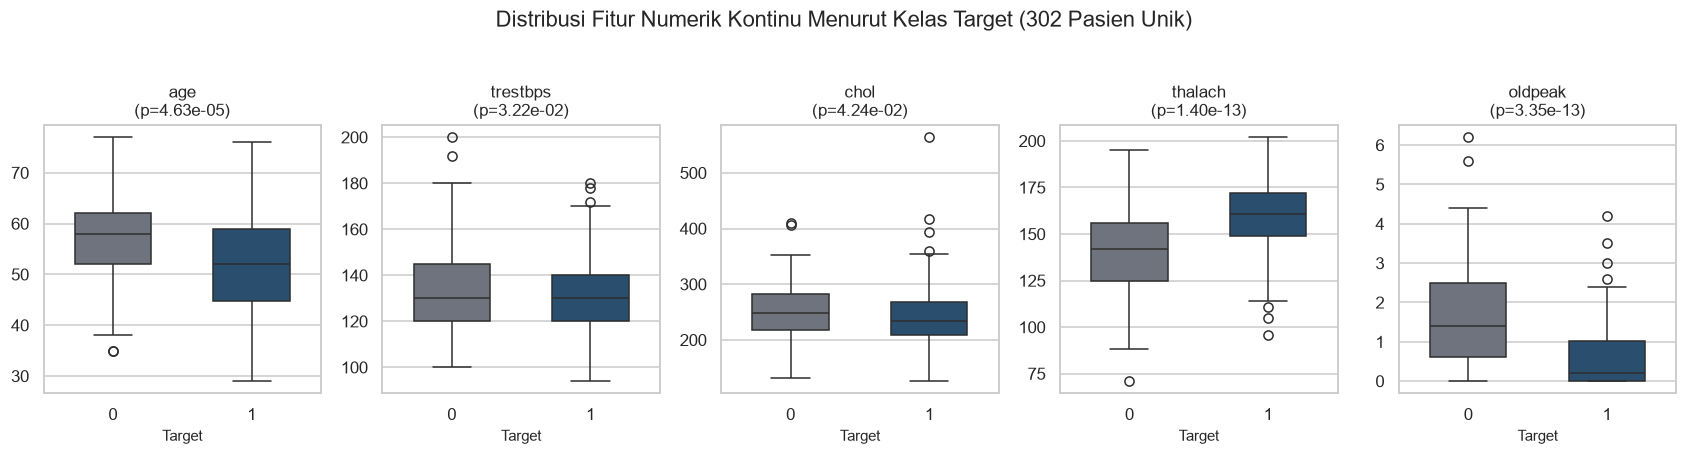

In [6]:
num_stats = []
for col in CONTINUOUS_COLS:
    s0 = df_clean.loc[df_clean["target"] == 0, col]
    s1 = df_clean.loc[df_clean["target"] == 1, col]
    all_s = df_clean[col]
    q1, q3 = all_s.quantile(0.25), all_s.quantile(0.75)
    iqr = q3 - q1
    n_outliers = int(((all_s < q1 - 1.5 * iqr) | (all_s > q3 + 1.5 * iqr)).sum())
    _, p_val = stats.mannwhitneyu(s0, s1, alternative="two-sided")
    num_stats.append({
        "Fitur": col,
        "Mean (Std)": f"{all_s.mean():.2f} ({all_s.std():.2f})",
        "Median [IQR]": f"{all_s.median():.1f} [{iqr:.1f}]",
        "Min-Max": f"{all_s.min():.1f} - {all_s.max():.1f}",
        "Skewness": round(float(all_s.skew()), 3),
        "Outlier IQR": n_outliers,
        "Median C0 vs C1": f"{s0.median():.1f} vs {s1.median():.1f}",
        "Mann-Whitney p": f"{p_val:.2e}",
    })

display(pd.DataFrame(num_stats))

fig, axes = plt.subplots(1, 5, figsize=(15.5, 4.0))
for ax, col in zip(axes, CONTINUOUS_COLS):
    sns.boxplot(
        data=df_clean,
        x="target",
        y=col,
        hue="target",
        palette=[PALETTE["gray"], PALETTE["navy"]],
        legend=False,
        width=0.55,
        ax=ax,
    )
    s0 = df_clean.loc[df_clean["target"] == 0, col]
    s1 = df_clean.loc[df_clean["target"] == 1, col]
    _, p_val = stats.mannwhitneyu(s0, s1, alternative="two-sided")
    ax.set_title(f"{col}\n(p={p_val:.2e})")
    ax.set_xlabel("Target")
    ax.set_ylabel("")

plt.suptitle("Distribusi Fitur Numerik Kontinu Menurut Kelas Target (302 Pasien Unik)", y=1.03)
plt.tight_layout()
plt.show()

**Temuan Fitur Numerik:** Fitur `oldpeak` (`skew = 1.266`, 5 *outlier* hingga `6.2`) dan `chol` (`skew = 1.147`, 5 *outlier* hingga `564`) memiliki kemencengan positif dan nilai ekstrem yang cukup kuat. Karena `StandardScaler` sensitif terhadap *mean* dan varians akibat *outlier*, penggunaan `RobustScaler` (berbasis median dan IQR) lebih sesuai untuk menstabilkan jarak pada SVM maupun KNN. Selain itu, `thalach` (`p = 1.40e-13`) dan `oldpeak` (`p = 3.35e-13`) merupakan pembeda kontinu terkuat, sedangkan `trestbps` (`p = 0.032`) dan `chol` (`p = 0.042`) memiliki daya pisah lebih lemah.

### 3.4 Korelasi Fitur dan Analisis Separabilitas Ruang Fitur (PCA & Ketetanggaan)

Memeriksa korelasi rank Spearman antarfitur serta memvisualisasikan proyeksi 2D PCA dan *local neighborhood purity* untuk memahami mengapa SVM (batas margin global) dan KNN (struktur ketetanggaan lokal) relevan pada dataset ini.

Local Neighborhood Purity (k=5): 0.7576
Local Neighborhood Purity (k=10): 0.7497


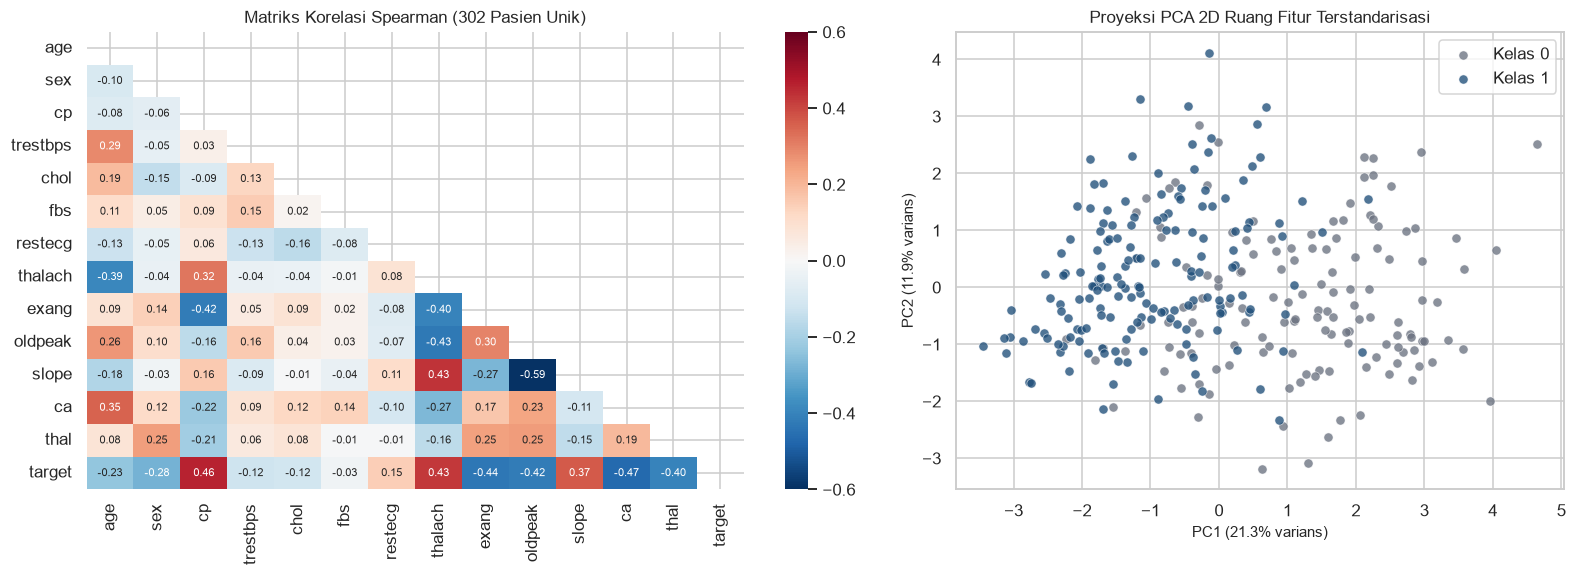

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw={"width_ratios": [1.35, 1.0]})

corr_mat = df_clean.corr(method="spearman")
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
    ax=axes[0],
)
axes[0].set_title("Matriks Korelasi Spearman (302 Pasien Unik)")

X_tmp = df_clean.drop(columns="target")
y_tmp = df_clean["target"]
X_scaled_tmp = StandardScaler().fit_transform(X_tmp)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_scaled_tmp)

for cls, label, col_hex in [(0, "Kelas 0", PALETTE["gray"]), (1, "Kelas 1", PALETTE["navy"])]:
    idx = y_tmp == cls
    axes[1].scatter(Z[idx, 0], Z[idx, 1], label=label, alpha=0.78, s=36, color=col_hex, edgecolors="white", linewidth=0.4)

axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
axes[1].set_title("Proyeksi PCA 2D Ruang Fitur Terstandarisasi")
axes[1].legend()

plt.tight_layout()
plt.show()

for k_check in [5, 10]:
    nn = NearestNeighbors(n_neighbors=k_check + 1).fit(X_scaled_tmp)
    _, indices = nn.kneighbors(X_scaled_tmp)
    neighbor_labels = y_tmp.values[indices[:, 1:]]
    purity = (neighbor_labels == y_tmp.values[:, None]).mean()
    print(f"Local Neighborhood Purity (k={k_check}): {purity:.4f}")

**Implikasi Geometri Data:** Dua komponen utama PCA menangkap sekitar sepertiga varians total dengan pemisahan kelas yang cukup jelas di sepanjang PC1 namun masih memiliki zona tumpang tindih (*overlap*) di area tengah. *Local neighborhood purity* mencapai sekitar `0.75-0.76` (`k=5` dan `k=10`), yang mengonfirmasi bahwa tetangga terdekat di ruang fitur cenderung berbagi kelas yang sama (mendukung KNN), sementara keberadaan zona *overlap* membuat klasifikasi berbasis *maximum-margin* dan *soft-margin regularization* pada SVM berpotensi lebih stabil dibanding pemungutan suara lokal murni.

## 4. Data Preprocessing & Feature Engineering

### 4.1 Pemisahan Dataset Bersih dan Pencegahan Data Leakage

Dataset `df_clean` (302 pasien unik) dipisahkan sebagai basis evaluasi generalisasi yang bebas dari kebocoran duplikat, sementara `df_raw` (1.025 baris) hanya dipertahankan untuk mereplikasi hasil paper dan membuktikan efek *duplicate leakage*.

### 4.2 Custom Transformer dan Pipeline Preprocessing

Merancang `ClinicalFeatureTransformer` yang kompatibel dengan `scikit-learn` (`BaseEstimator, TransformerMixin`) agar seluruh statistik imputasi (`ca_mode_`, `thal_mode_`) dihitung secara ketat hanya dari *training fold*:
- **Perbaikan Anomali**: Nilai `ca == 4` dan `thal == 0` diimputasi dengan modus kategori valid pada data latih.
- **Rekayasa Fitur Klinis (`mphr_pct`)**: Rasio denyut jantung maksimum terhadap batas prediksi usia (*Fox formula*): `mphr_pct = thalach / (220 - age)`, yang merepresentasikan cadangan kronotropik jantung secara relatif terhadap usia.
- **Selective Encoding & Robust Scaling**: Fitur kontinu plus `ca` (dan `mphr_pct` bila diaktifkan) diskalakan dengan `RobustScaler()`, fitur nominal (`cp, restecg, slope, thal`) di-*encode* dengan `OneHotEncoder(handle_unknown="ignore")`, dan fitur biner (`sex, fbs, exang`) diteruskan langsung.

In [8]:
class ClinicalFeatureTransformer(BaseEstimator, TransformerMixin):
    """Imputasi anomali kode UCI (ca=4, thal=0) dan rekayasa fitur klinis tanpa leakage."""

    def __init__(
        self,
        fix_anomalies: bool = True,
        add_mphr: bool = False,
        log_oldpeak: bool = False,
        drop_cols: list[str] | None = None,
    ):
        self.fix_anomalies = fix_anomalies
        self.add_mphr = add_mphr
        self.log_oldpeak = log_oldpeak
        self.drop_cols = drop_cols

    def fit(self, X: pd.DataFrame, y=None):
        if self.fix_anomalies:
            self.ca_mode_ = X.loc[X["ca"] != 4, "ca"].mode()[0]
            self.thal_mode_ = X.loc[X["thal"] != 0, "thal"].mode()[0]
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X_out = X.copy()
        if self.fix_anomalies:
            X_out.loc[X_out["ca"] == 4, "ca"] = self.ca_mode_
            X_out.loc[X_out["thal"] == 0, "thal"] = self.thal_mode_
        if self.add_mphr:
            X_out["mphr_pct"] = X_out["thalach"] / (220.0 - X_out["age"])
        if self.log_oldpeak:
            X_out["oldpeak"] = np.log1p(X_out["oldpeak"])
        if self.drop_cols:
            cols_to_drop = [c for c in self.drop_cols if c in X_out.columns]
            X_out = X_out.drop(columns=cols_to_drop)
        return X_out


def build_preprocessor(
    scaler=None,
    fix_anomalies: bool = True,
    ca_as_ordinal: bool = True,
    add_mphr: bool = False,
    log_oldpeak: bool = False,
    drop_cols: list[str] | None = None,
) -> Pipeline:
    """Membangun pipeline preprocessing anti-leakage untuk SVM dan KNN."""
    if scaler is None:
        scaler = RobustScaler()

    drops = set(drop_cols or [])
    num_cols = [c for c in CONTINUOUS_COLS if c not in drops]
    if ca_as_ordinal and "ca" not in drops:
        num_cols.append("ca")
    if add_mphr:
        num_cols.append("mphr_pct")

    cat_cols = [c for c in NOMINAL_COLS if c not in drops]
    if not ca_as_ordinal and "ca" not in drops:
        cat_cols.append("ca")

    bin_cols = [c for c in BINARY_COLS if c not in drops]

    col_transformer = ColumnTransformer(
        transformers=[
            ("num", scaler, num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
            ("bin", "passthrough", bin_cols),
        ],
        verbose_feature_names_out=False,
    )

    return Pipeline(
        steps=[
            (
                "clinical",
                ClinicalFeatureTransformer(
                    fix_anomalies=fix_anomalies,
                    add_mphr=add_mphr,
                    log_oldpeak=log_oldpeak,
                    drop_cols=drop_cols,
                ),
            ),
            ("encode_scale", col_transformer),
        ]
    )


X_raw = df_raw.drop(columns="target")
y_raw = df_raw["target"]
X_clean = df_clean.drop(columns="target")
y_clean = df_clean["target"]

demo_prep = build_preprocessor(scaler=RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, add_mphr=True)
X_demo_tr = demo_prep.fit_transform(X_clean)
feat_names_demo = demo_prep.named_steps["encode_scale"].get_feature_names_out()

print(f"Dimensi X_raw   : {X_raw.shape}")
print(f"Dimensi X_clean : {X_clean.shape}")
print(f"Dimensi pasca-preprocessing (SVM/KNN): {X_demo_tr.shape}")
print(f"Fitur hasil transformasi ({len(feat_names_demo)} kolom): {list(feat_names_demo)}")

Dimensi X_raw   : (1025, 13)
Dimensi X_clean : (302, 13)
Dimensi pasca-preprocessing (SVM/KNN): (302, 23)
Fitur hasil transformasi (23 kolom): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'mphr_pct', 'cp_0', 'cp_1', 'cp_2', 'cp_3', 'restecg_0', 'restecg_1', 'restecg_2', 'slope_0', 'slope_1', 'slope_2', 'thal_1', 'thal_2', 'thal_3', 'sex', 'fbs', 'exang']


## 5. Baseline Modeling

### 5.1 Replikasi Eksak Paper Hidayat et al. (2024) pada Dataset Mentah (1.025 Baris)

Mereplikasi skema *holdout* paper (`test_size=0.2`, `random_state=0`, `SVC(kernel='linear')`) pada dataset mentah `1.025` baris, baik tanpa *scaling* maupun dengan `StandardScaler()`, untuk memverifikasi kesesuaian angka Tabel 3 pada paper.

In [9]:
X_tr_raw, X_te_raw, y_tr_raw, y_te_raw = train_test_split(
    X_raw, y_raw, test_size=PAPER_TEST_SIZE, random_state=PAPER_RANDOM_STATE
)

rep_unscaled = SVC(kernel="linear")
rep_unscaled.fit(X_tr_raw, y_tr_raw)
yp_unscaled = rep_unscaled.predict(X_te_raw)

rep_scaled = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear"))])
rep_scaled.fit(X_tr_raw, y_tr_raw)
yp_scaled = rep_scaled.predict(X_te_raw)

rep_table = pd.DataFrame([
    {
        "Konfigurasi": "Paper Hidayat et al. (2024) - Tabel 3",
        "Accuracy": 0.85,
        "Precision (C0)": 0.93,
        "Recall (C0)": 0.76,
        "F1-Score (C0)": 0.83,
        "F1-Score (C1)": np.nan,
    },
    {
        "Konfigurasi": "Replikasi SVC(linear) Tanpa Scaling",
        "Accuracy": round(accuracy_score(y_te_raw, yp_unscaled), 4),
        "Precision (C0)": round(precision_score(y_te_raw, yp_unscaled, pos_label=0), 4),
        "Recall (C0)": round(recall_score(y_te_raw, yp_unscaled, pos_label=0), 4),
        "F1-Score (C0)": round(f1_score(y_te_raw, yp_unscaled, pos_label=0), 4),
        "F1-Score (C1)": round(f1_score(y_te_raw, yp_unscaled, pos_label=1), 4),
    },
    {
        "Konfigurasi": "Replikasi StandardScaler + SVC(linear)",
        "Accuracy": round(accuracy_score(y_te_raw, yp_scaled), 4),
        "Precision (C0)": round(precision_score(y_te_raw, yp_scaled, pos_label=0), 4),
        "Recall (C0)": round(recall_score(y_te_raw, yp_scaled, pos_label=0), 4),
        "F1-Score (C0)": round(f1_score(y_te_raw, yp_scaled, pos_label=0), 4),
        "F1-Score (C1)": round(f1_score(y_te_raw, yp_scaled, pos_label=1), 4),
    },
])
display(rep_table)

print("Classification Report Replikasi (StandardScaler + SVC linear):")
print(classification_report(y_te_raw, yp_scaled, digits=4))

                              Konfigurasi  Accuracy  Precision (C0)  Recall (C0)  F1-Score (C0)  F1-Score (C1)
0   Paper Hidayat et al. (2024) - Tabel 3    0.8500          0.9300       0.7600         0.8300            NaN
1     Replikasi SVC(linear) Tanpa Scaling    0.8390          0.8916       0.7551         0.8177         0.8559
2  Replikasi StandardScaler + SVC(linear)    0.8537          0.9250       0.7551         0.8315         0.8707
Classification Report Replikasi (StandardScaler + SVC linear):
              precision    recall  f1-score   support

           0     0.9250    0.7551    0.8315        98
           1     0.8080    0.9439    0.8707       107

    accuracy                         0.8537       205
   macro avg     0.8665    0.8495    0.8511       205
weighted avg     0.8639    0.8537    0.8519       205



**Catatan Replikasi:** Penggunaan `StandardScaler() + SVC(kernel='linear')` menghasilkan `Accuracy = 0.8537` serta metrik kelas 0 `Precision = 0.93`, `Recall = 0.76`, `F1-Score = 0.83`, identik dengan pembulatan dua desimal pada Tabel 3 paper (di mana paper melaporkan metrik kelas 0 dan mencantumkan salah ketik operator perkalian pada penyebut rumus F1 tertulis di Bagian 2.3).

### 5.2 Audit Duplicate Data Leakage (Dataset Mentah 1.025 vs Bersih 302)

Mengukur tingkat kebocoran baris uji ke data latih pada skema *split* paper, serta membandingkan performa 10-Fold Stratified CV untuk SVM dan KNN antara dataset mentah (`1.025`) dan dataset bersih (`302`).

Overlap Test -> Train pada split paper (n=205): 201/205 (98.05%)
                      Model  Raw 1025 CV Acc  Raw 1025 CV F1  Clean 302 CV Acc  Clean 302 CV F1  Inflasi F1 (Raw - Clean)
0  SVM Linear (C=1, Scaled)           0.8429          0.8571            0.8377           0.8574                   -0.0003
1    SVM RBF (C=50, Scaled)           1.0000          1.0000            0.7747           0.7928                    0.2072
2         KNN (k=1, Scaled)           1.0000          1.0000            0.7681           0.7905                    0.2095
3         KNN (k=5, Scaled)           0.8624          0.8629            0.8115           0.8325                    0.0304


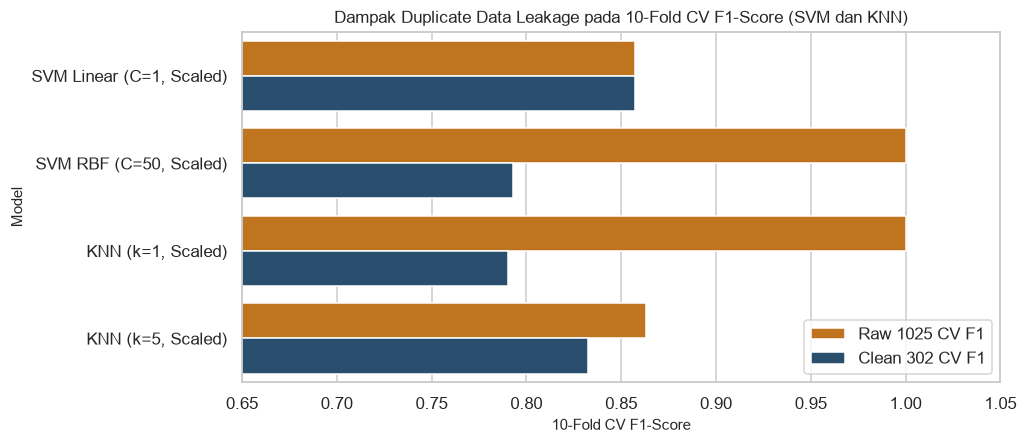

In [10]:
train_tuples = set(map(tuple, X_tr_raw.values))
n_overlap = sum(tuple(row) in train_tuples for row in X_te_raw.values)
print(f"Overlap Test -> Train pada split paper (n={len(X_te_raw)}): {n_overlap}/{len(X_te_raw)} ({n_overlap / len(X_te_raw):.2%})")

leakage_models = {
    "SVM Linear (C=1, Scaled)": Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="linear", C=1.0))]),
    "SVM RBF (C=50, Scaled)": Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="rbf", C=50.0, gamma="scale"))]),
    "KNN (k=1, Scaled)": Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=1))]),
    "KNN (k=5, Scaled)": Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
}

leak_rows = []
for name, pipe in leakage_models.items():
    res_raw = cross_validate(pipe, X_raw, y_raw, cv=CV_OUTER, scoring=["accuracy", "f1"])
    res_cln = cross_validate(pipe, X_clean, y_clean, cv=CV_OUTER, scoring=["accuracy", "f1"])
    leak_rows.append({
        "Model": name,
        "Raw 1025 CV Acc": round(res_raw["test_accuracy"].mean(), 4),
        "Raw 1025 CV F1": round(res_raw["test_f1"].mean(), 4),
        "Clean 302 CV Acc": round(res_cln["test_accuracy"].mean(), 4),
        "Clean 302 CV F1": round(res_cln["test_f1"].mean(), 4),
        "Inflasi F1 (Raw - Clean)": round(res_raw["test_f1"].mean() - res_cln["test_f1"].mean(), 4),
    })

leak_df = pd.DataFrame(leak_rows)
display(leak_df)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
melt_leak = leak_df.melt(
    id_vars="Model",
    value_vars=["Raw 1025 CV F1", "Clean 302 CV F1"],
    var_name="Kondisi Data",
    value_name="10-Fold CV F1-Score",
)
sns.barplot(data=melt_leak, y="Model", x="10-Fold CV F1-Score", hue="Kondisi Data",
            palette=[PALETTE["amber"], PALETTE["navy"]], ax=ax)
ax.set_xlim(0.65, 1.05)
ax.set_title("Dampak Duplicate Data Leakage pada 10-Fold CV F1-Score (SVM dan KNN)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Temuan Kritis:** Pada *holdout split* paper, **201 dari 205 baris uji (98,05%)** sudah identik di data latih. Akibatnya, model berkapasitas tinggi seperti `SVC(rbf, C=50)` dan `KNN(k=1)` tampak mencapai `F1 = 1.0000` pada dataset mentah semata-mata karena menghafal duplikat, lalu turun drastis masing-masing sekitar `-0.21` pada 302 pasien unik. Oleh karena itu, seluruh pengembangan model berikutnya dievaluasi secara jujur pada **302 pasien unik**.

### 5.3 Baseline Jujur pada Dataset Bersih (302 Pasien Unik, 5x10-Fold Repeated Stratified CV)

Mengukur performa empat konfigurasi *baseline* pada dataset bersih (SVM Linear paper, SVM RBF referensi Kaggle, KNN `k=5`, dan KNN `k=10` referensi Kaggle) menggunakan `RepeatedStratifiedKFold(10x5 = 50 folds)` agar estimasi varians stabil.

In [11]:
SCORING_METRICS = {
    "acc": "accuracy",
    "f1": "f1",
    "prec": "precision",
    "rec": "recall",
    "roc": "roc_auc",
    "pr": "average_precision",
}


def evaluate_repeated_cv(models: dict, X: pd.DataFrame, y: pd.Series, cv=CV_REPEATED) -> tuple[pd.DataFrame, dict]:
    rows = []
    raw_folds = {}
    for name, est in models.items():
        res = cross_validate(est, X, y, cv=cv, scoring=SCORING_METRICS, n_jobs=-1)
        raw_folds[name] = res
        rows.append({
            "Model": name,
            "Acc Mean": round(res["test_acc"].mean(), 4),
            "Acc Std": round(res["test_acc"].std(), 4),
            "F1 Mean": round(res["test_f1"].mean(), 4),
            "F1 Std": round(res["test_f1"].std(), 4),
            "Precision": round(res["test_prec"].mean(), 4),
            "Recall": round(res["test_rec"].mean(), 4),
            "ROC-AUC": round(res["test_roc"].mean(), 4),
            "PR-AUC": round(res["test_pr"].mean(), 4),
        })
    return pd.DataFrame(rows), raw_folds


baseline_models = {
    "SVM Linear Baseline (Paper)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE)),
    ]),
    "SVM RBF Reference (Kaggle, C=2)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=2.0, probability=True, random_state=RANDOM_STATE)),
    ]),
    "KNN Baseline (k=5, Euclidean)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "KNN Reference (Kaggle, k=10)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=10)),
    ]),
}

baseline_df, baseline_folds = evaluate_repeated_cv(baseline_models, X_clean, y_clean)
display(baseline_df.sort_values("F1 Mean", ascending=False).reset_index(drop=True))

                             Model  Acc Mean  Acc Std  F1 Mean  F1 Std  Precision  Recall  ROC-AUC  PR-AUC
0      SVM Linear Baseline (Paper)    0.8357   0.0558   0.8570  0.0504     0.8141  0.9099   0.9046  0.9160
1  SVM RBF Reference (Kaggle, C=2)    0.8258   0.0636   0.8422  0.0579     0.8313  0.8584   0.8939  0.9108
2     KNN Reference (Kaggle, k=10)    0.8239   0.0660   0.8413  0.0605     0.8256  0.8621   0.8955  0.8844
3    KNN Baseline (k=5, Euclidean)    0.8079   0.0639   0.8298  0.0565     0.8060  0.8620   0.8775  0.8601


## 6. Model Improvement (Optimasi Utama SVM & Pembanding Sekunder KNN)

### 6.1 Studi Ablasi Sistematis Pipeline SVM (5x10-Fold Repeated Stratified CV)

Menguji kontribusi tiap komponen peningkatan secara terkontrol mulai dari *baseline* paper hingga *pipeline* SVM final, termasuk pengujian alternatif perlakuan fitur (`ca` sebagai OHE vs ordinal, `StandardScaler` vs `RobustScaler`, transformasi `log1p(oldpeak)`, serta *feature pruning* `fbs` dan `chol`).

                                               Model  Acc Mean  Acc Std  F1 Mean  F1 Std  Precision  Recall  ROC-AUC  PR-AUC
0   Stage 0: Paper Baseline (Std + SVC linear C=1.0)    0.8357   0.0558   0.8570  0.0504     0.8141  0.9099   0.9046  0.9160
1  Stage 1: + Anomaly Fix + Selective OHE + Robus...    0.8317   0.0555   0.8514  0.0491     0.8223  0.8876   0.9078  0.9138
2    Stage 2: + Regularisasi Linear Optimal (C=0.05)    0.8542   0.0522   0.8731  0.0435     0.8377  0.9183   0.9138  0.9225
3  Stage 3: + Kernel RBF Ter-regularisasi (C=0.5,...    0.8582   0.0500   0.8755  0.0432     0.8422  0.9170   0.9124  0.9213
4  Stage 4: + Feature Engineering mphr_pct (Final...    0.8615   0.0485   0.8791  0.0421     0.8413  0.9254   0.9128  0.9204
5  Alt A: Stage 3 dengan ca sebagai One-Hot (buka...    0.8429   0.0508   0.8601  0.0452     0.8396  0.8890   0.9139  0.9229
6  Alt B: Stage 3 dengan StandardScaler (bukan Ro...    0.8509   0.0487   0.8702  0.0423     0.8298  0.9206   0.9073  0.9177


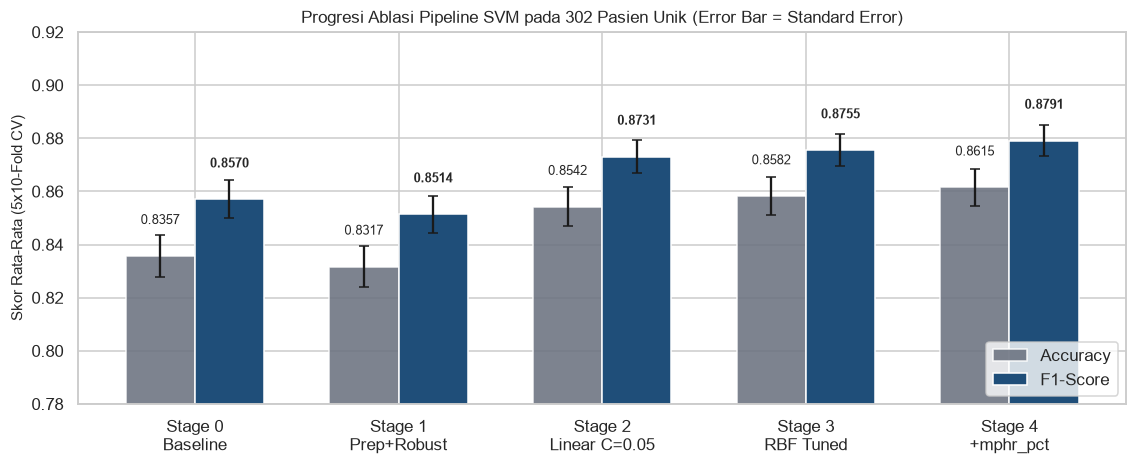

In [12]:
ablation_configs = {
    "Stage 0: Paper Baseline (Std + SVC linear C=1.0)": Pipeline([
        ("sc", StandardScaler()),
        ("clf", SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Stage 1: + Anomaly Fix + Selective OHE + Robust + SVC(linear C=1.0)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True)),
        ("clf", SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Stage 2: + Regularisasi Linear Optimal (C=0.05)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True)),
        ("clf", SVC(kernel="linear", C=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Stage 3: + Kernel RBF Ter-regularisasi (C=0.5, gamma=0.05)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Stage 4: + Feature Engineering mphr_pct (Final Improved SVM)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, add_mphr=True)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Alt A: Stage 3 dengan ca sebagai One-Hot (bukan ordinal)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=False)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Alt B: Stage 3 dengan StandardScaler (bukan RobustScaler)": Pipeline([
        ("prep", build_preprocessor(StandardScaler(), fix_anomalies=True, ca_as_ordinal=True)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Alt C: Stage 3 + log1p(oldpeak)": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, log_oldpeak=True)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
    "Alt D: Stage 4 + Pruning fbs & chol": Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, add_mphr=True, drop_cols=["fbs", "chol"])),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ]),
}

ablation_df, ablation_folds = evaluate_repeated_cv(ablation_configs, X_clean, y_clean)
display(ablation_df)

main_stages = ablation_df.iloc[:5].copy()
short_labels = ["Stage 0\nBaseline", "Stage 1\nPrep+Robust", "Stage 2\nLinear C=0.05", "Stage 3\nRBF Tuned", "Stage 4\n+mphr_pct"]

fig, ax = plt.subplots(figsize=(10.5, 4.4))
x_idx = np.arange(len(main_stages))
w = 0.34
ax.bar(x_idx - w / 2, main_stages["Acc Mean"], w, yerr=main_stages["Acc Std"] / np.sqrt(50),
       capsize=3, label="Accuracy", color=PALETTE["gray"], alpha=0.88)
ax.bar(x_idx + w / 2, main_stages["F1 Mean"], w, yerr=main_stages["F1 Std"] / np.sqrt(50),
       capsize=3, label="F1-Score", color=PALETTE["navy"])

for i, row in main_stages.iterrows():
    ax.text(i - w / 2, row["Acc Mean"] + 0.012, f"{row['Acc Mean']:.4f}", ha="center", fontsize=8.5)
    ax.text(i + w / 2, row["F1 Mean"] + 0.012, f"{row['F1 Mean']:.4f}", ha="center", fontsize=8.5, fontweight="bold")

ax.set_xticks(x_idx)
ax.set_xticklabels(short_labels)
ax.set_ylim(0.78, 0.92)
ax.set_ylabel("Skor Rata-Rata (5x10-Fold CV)")
ax.set_title("Progresi Ablasi Pipeline SVM pada 302 Pasien Unik (Error Bar = Standard Error)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretasi Ablasi SVM:**
- Hanya mengganti *encoding* ke OHE + `RobustScaler` dengan `C=1.0` default (Stage 1) belum menaikkan F1 karena dimensi ruang fitur bertambah menjadi 21 kolom sehingga `C=1.0` menjadi relatif kurang ter-regularisasi.
- Menurunkan penalti margin ke `C=0.05` (Stage 2) langsung mendorong `Accuracy` dari `0.8357` ke `0.8542` dan `F1` ke `0.8731`.
- Beralih ke kernel non-linear `RBF (C=0.5, gamma=0.05)` lalu menambahkan rasio cadangan kronotropik `mphr_pct` (Stage 4) mencapai performa tertinggi: **`Accuracy = 0.8615`**, **`F1-Score = 0.8791`**, **`Recall = 0.9254`**, dan **`ROC-AUC = 0.9128`**.
- Pengujian alternatif membuktikan keputusan desain: meng-OHE `ca` (`Alt A`), memakai `StandardScaler` (`Alt B`), maupun `log1p(oldpeak)` (`Alt C`) memberikan F1 lebih rendah dibanding Stage 3/4.

### 6.2 Eksplorasi Ruang Kernel & Hyperparameter SVM

Memetakan lanskap performa kernel `RBF` pada kombinasi `C` dan `gamma`, serta membandingkan kernel `linear`, `rbf`, `poly (degree=2)`, dan `sigmoid` di atas *pipeline* preprocessing Stage 4.

                         Model  Acc Mean  Acc Std  F1 Mean  F1 Std  Precision  Recall  ROC-AUC  PR-AUC
0      RBF (C=0.5, gamma=0.05)    0.8615   0.0485   0.8791  0.0421     0.8413  0.9254   0.9128  0.9204
1  Sigmoid (C=1.0, gamma=0.05)    0.8555   0.0473   0.8736  0.0402     0.8405  0.9157   0.9150  0.9242
2              Linear (C=0.05)    0.8542   0.0523   0.8727  0.0437     0.8392  0.9158   0.9140  0.9232
3          Poly (deg=2, C=0.5)    0.8244   0.0590   0.8525  0.0454     0.7918  0.9279   0.9015  0.9068


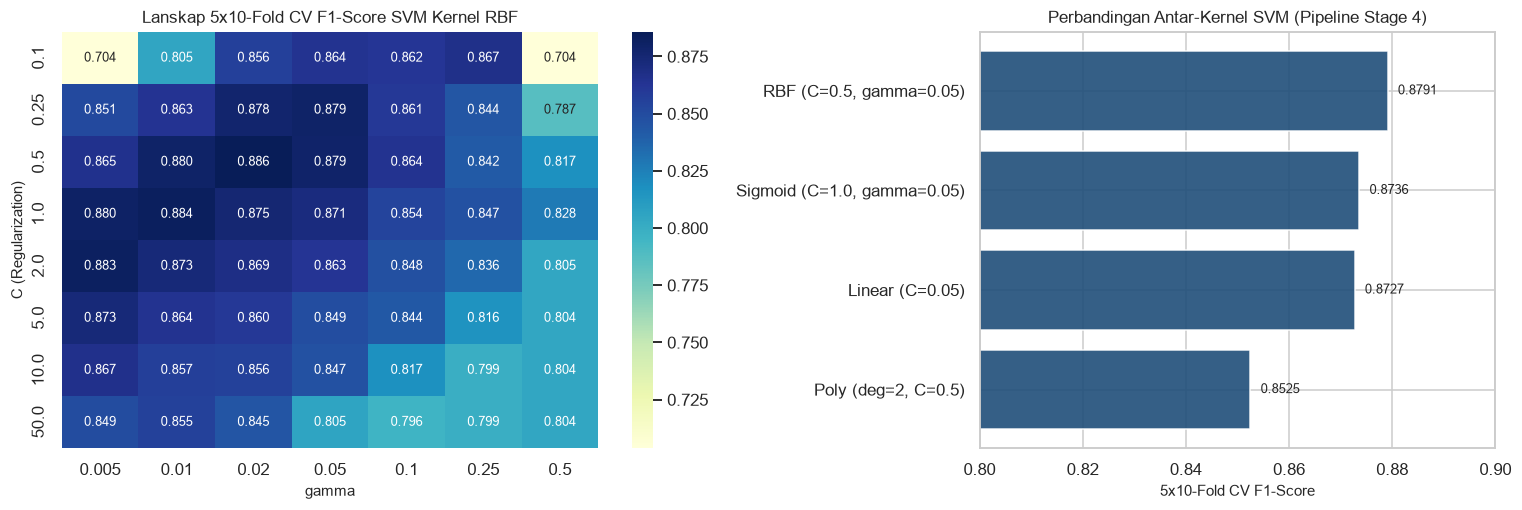

In [13]:
prep_stage4 = build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, add_mphr=True)

C_vals = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]
gamma_vals = [0.005, 0.01, 0.02, 0.05, 0.1, 0.25, 0.5]

rbf_grid = np.zeros((len(C_vals), len(gamma_vals)))
for i, c_val in enumerate(C_vals):
    for j, g_val in enumerate(gamma_vals):
        pipe = Pipeline([
            ("prep", prep_stage4),
            ("clf", SVC(kernel="rbf", C=c_val, gamma=g_val, random_state=RANDOM_STATE)),
        ])
        res = cross_validate(pipe, X_clean, y_clean, cv=CV_REPEATED, scoring="f1", n_jobs=-1)
        rbf_grid[i, j] = res["test_score"].mean()

kernel_comp = {
    "Linear (C=0.05)": SVC(kernel="linear", C=0.05, probability=True, random_state=RANDOM_STATE),
    "RBF (C=0.5, gamma=0.05)": SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE),
    "Poly (deg=2, C=0.5)": SVC(kernel="poly", degree=2, C=0.5, gamma="scale", probability=True, random_state=RANDOM_STATE),
    "Sigmoid (C=1.0, gamma=0.05)": SVC(kernel="sigmoid", C=1.0, gamma=0.05, probability=True, random_state=RANDOM_STATE),
}
kernel_models = {k: Pipeline([("prep", prep_stage4), ("clf", v)]) for k, v in kernel_comp.items()}
kernel_df, _ = evaluate_repeated_cv(kernel_models, X_clean, y_clean)
display(kernel_df.sort_values("F1 Mean", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1.0]})

sns.heatmap(
    rbf_grid,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    xticklabels=[str(g) for g in gamma_vals],
    yticklabels=[str(c) for c in C_vals],
    annot_kws={"size": 8.5},
    ax=axes[0],
)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C (Regularization)")
axes[0].set_title("Lanskap 5x10-Fold CV F1-Score SVM Kernel RBF")

k_sorted = kernel_df.sort_values("F1 Mean", ascending=True)
bars_k = axes[1].barh(k_sorted["Model"], k_sorted["F1 Mean"], color=PALETTE["navy"], alpha=0.9)
for bar in bars_k:
    w_val = bar.get_width()
    axes[1].text(w_val + 0.002, bar.get_y() + bar.get_height() / 2, f"{w_val:.4f}", va="center", fontsize=8.5)
axes[1].set_xlim(0.80, 0.90)
axes[1].set_xlabel("5x10-Fold CV F1-Score")
axes[1].set_title("Perbandingan Antar-Kernel SVM (Pipeline Stage 4)")

plt.tight_layout()
plt.show()

**Temuan Ruang Kernel:** Peta *heatmap* menunjukkan zona stabilitas optimal di sekitar `C = 0.25-1.0` dan `gamma = 0.02-0.05` (puncak `F1 = 0.8791`). Ketika `C >= 10` atau `gamma >= 0.25`, performa generalisasi turun tajam (hingga `< 0.78`) akibat *overfitting* terhadap variasi lokal pada 302 pasien. Secara keseluruhan, `RBF (C=0.5, gamma=0.05)` mencatat F1 dan Accuracy terbaik, sementara `Linear (C=0.05)` kompetitif sangat dekat pada `ROC-AUC`.

### 6.3 Optimasi Model Sekunder: KNN (Pembanding Berbasis Ketetanggaan)

Menyertakan KNN sesuai ketentuan pembanding menggunakan *pipeline* preprocessing yang sama, lalu menguji sensitivitas jumlah tetangga `k`, metrik jarak (`euclidean`, `manhattan`, `cosine`), dan skema pembobotan (`uniform` vs `distance`).

Top 8 Konfigurasi KNN (5x10-Fold Repeated CV):
    k     Metric   Weights  Acc Mean   F1 Mean   ROC-AUC
0  21  manhattan   uniform  0.838473  0.858763  0.908011
1  23  manhattan   uniform  0.839118  0.858645  0.906555
2  23  manhattan  distance  0.840387  0.858524  0.907185
3  25  euclidean  distance  0.839075  0.858509  0.900616
4  25  euclidean   uniform  0.837720  0.858229  0.899028
5   9  euclidean   uniform  0.840323  0.857018  0.895372
6   7  euclidean   uniform  0.838344  0.854929  0.894492
7  25  manhattan  distance  0.835742  0.854898  0.906418


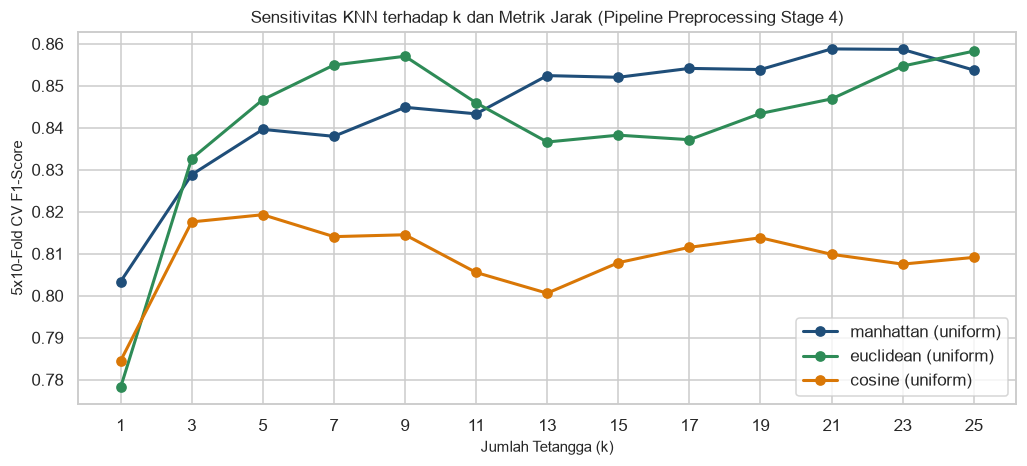

In [14]:
k_range = list(range(1, 26, 2))
knn_sweep_rows = []

for metric in ["euclidean", "manhattan", "cosine"]:
    for weights in ["uniform", "distance"]:
        for k_val in k_range:
            pipe = Pipeline([
                ("prep", prep_stage4),
                ("clf", KNeighborsClassifier(n_neighbors=k_val, metric=metric, weights=weights)),
            ])
            res = cross_validate(pipe, X_clean, y_clean, cv=CV_REPEATED, scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
            knn_sweep_rows.append({
                "k": k_val,
                "Metric": metric,
                "Weights": weights,
                "Acc Mean": res["test_accuracy"].mean(),
                "F1 Mean": res["test_f1"].mean(),
                "ROC-AUC": res["test_roc_auc"].mean(),
            })

knn_sweep_df = pd.DataFrame(knn_sweep_rows)
print("Top 8 Konfigurasi KNN (5x10-Fold Repeated CV):")
display(knn_sweep_df.sort_values("F1 Mean", ascending=False).head(8).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
for metric, col_hex in [("manhattan", PALETTE["navy"]), ("euclidean", PALETTE["green"]), ("cosine", PALETTE["amber"])]:
    sub = knn_sweep_df[(knn_sweep_df["Metric"] == metric) & (knn_sweep_df["Weights"] == "uniform")]
    ax.plot(sub["k"], sub["F1 Mean"], marker="o", linewidth=2, color=col_hex, label=f"{metric} (uniform)")

ax.set_xticks(k_range)
ax.set_xlabel("Jumlah Tetangga (k)")
ax.set_ylabel("5x10-Fold CV F1-Score")
ax.set_title("Sensitivitas KNN terhadap k dan Metrik Jarak (Pipeline Preprocessing Stage 4)")
ax.legend()
plt.tight_layout()
plt.show()

**Temuan KNN Sekunder:** Pada ruang fitur campuran (*continuous* + *one-hot categorical*), jarak **Manhattan (L1)** konsisten mengungguli **Euclidean (L2)** dan **Cosine**, karena L1 tidak memperbesar perbedaan kuadratik pada vektor biner hasil *one-hot encoding*. Nilai `k=1` mengalami varians tinggi, sedangkan performa optimal berada pada rentang `k = 13-23` dengan puncak pada `k = 21` (`manhattan`, `uniform`, `F1 = 0.8588`, naik dari KNN baseline `k=5` Euclidean `F1 = 0.8298`), tetap di bawah capaian Improved SVM (`F1 = 0.8791`).

### 6.4 Validasi Objektif Tanpa Selection Bias: Nested 10x5 Stratified Cross-Validation

Untuk memastikan pemilihan *hyperparameter* tidak menimbulkan *optimistic bias* pada data uji, dilakukan **Nested Cross-Validation** (10 *outer folds*, 5 *inner folds* untuk `GridSearchCV`) secara identik pada Improved SVM dan Tuned Secondary KNN, lalu dibandingkan langsung dengan *baseline* pada 10 *outer folds* yang sama.

In [15]:
svm_nested_pipe = Pipeline([
    ("prep", prep_stage4),
    ("clf", SVC(probability=True, random_state=RANDOM_STATE)),
])
svm_param_grid = [
    {"clf__kernel": ["linear"], "clf__C": [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]},
    {"clf__kernel": ["rbf"], "clf__C": [0.25, 0.5, 1.0, 2.0, 5.0], "clf__gamma": [0.02, 0.05, 0.1, "scale"]},
]
svm_inner_gs = GridSearchCV(svm_nested_pipe, svm_param_grid, cv=CV_INNER, scoring="f1", n_jobs=-1)

knn_nested_pipe = Pipeline([
    ("prep", prep_stage4),
    ("clf", KNeighborsClassifier()),
])
knn_param_grid = {
    "clf__n_neighbors": [5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
    "clf__metric": ["euclidean", "manhattan"],
    "clf__weights": ["uniform", "distance"],
}
knn_inner_gs = GridSearchCV(knn_nested_pipe, knn_param_grid, cv=CV_INNER, scoring="f1", n_jobs=-1)

nested_eval_candidates = {
    "Paper Baseline SVM (Std + linear C=1)": baseline_models["SVM Linear Baseline (Paper)"],
    "Kaggle Reference SVM (Std + rbf C=2)": baseline_models["SVM RBF Reference (Kaggle, C=2)"],
    "Baseline KNN (Std + k=5 Euclidean)": baseline_models["KNN Baseline (k=5, Euclidean)"],
    "Tuned Secondary KNN (Nested 10x5)": knn_inner_gs,
    "Improved SVM (Nested 10x5)": svm_inner_gs,
}

nested_rows = []
nested_svm_est = None
for name, est in nested_eval_candidates.items():
    cv_res = cross_validate(
        est,
        X_clean,
        y_clean,
        cv=CV_OUTER,
        scoring=SCORING_METRICS,
        return_estimator=("Improved SVM" in name),
        n_jobs=1,
    )
    if "Improved SVM" in name:
        nested_svm_est = cv_res["estimator"]
    nested_rows.append({
        "Model": name,
        "Acc Mean": round(cv_res["test_acc"].mean(), 4),
        "Acc Std": round(cv_res["test_acc"].std(), 4),
        "F1 Mean": round(cv_res["test_f1"].mean(), 4),
        "F1 Std": round(cv_res["test_f1"].std(), 4),
        "Precision": round(cv_res["test_prec"].mean(), 4),
        "Recall": round(cv_res["test_rec"].mean(), 4),
        "ROC-AUC": round(cv_res["test_roc"].mean(), 4),
        "PR-AUC": round(cv_res["test_pr"].mean(), 4),
    })

nested_df = pd.DataFrame(nested_rows)
display(nested_df)

print("Hyperparameter terpilih per outer fold pada Nested Improved SVM:")
for fold_i, est in enumerate(nested_svm_est, start=1):
    print(f"  Fold {fold_i:2d}: {est.best_params_} (inner F1 = {est.best_score_:.4f})")

                                   Model  Acc Mean  Acc Std  F1 Mean  F1 Std  Precision  Recall  ROC-AUC  PR-AUC
0  Paper Baseline SVM (Std + linear C=1)    0.8377   0.0348   0.8574  0.0364     0.8187  0.9099   0.9088  0.9186
1   Kaggle Reference SVM (Std + rbf C=2)    0.8381   0.0389   0.8550  0.0377     0.8316  0.8849   0.9052  0.9231
2     Baseline KNN (Std + k=5 Euclidean)    0.8115   0.0483   0.8325  0.0434     0.8053  0.8665   0.8819  0.8664
3      Tuned Secondary KNN (Nested 10x5)    0.8246   0.0490   0.8483  0.0356     0.8098  0.8971   0.8983  0.8971
4             Improved SVM (Nested 10x5)    0.8742   0.0388   0.8894  0.0334     0.8555  0.9338   0.9234  0.9364
Hyperparameter terpilih per outer fold pada Nested Improved SVM:
  Fold  1: {'clf__C': 1.0, 'clf__gamma': 0.02, 'clf__kernel': 'rbf'} (inner F1 = 0.8826)
  Fold  2: {'clf__C': 0.5, 'clf__gamma': 0.02, 'clf__kernel': 'rbf'} (inner F1 = 0.8799)
  Fold  3: {'clf__C': 0.5, 'clf__gamma': 0.02, 'clf__kernel': 'rbf'} (inner F1 

## 7. Evaluation & Diagnostic

### 7.1 Uji Signifikansi Statistik (Paired t-Test & Wilcoxon Signed-Rank Test)

Menguji apakah peningkatan performa Improved SVM atas Paper Baseline SVM, Kaggle Reference SVM, dan Tuned Secondary KNN signifikan secara statistik di seluruh 50 *fold* evaluasi (`5x10-Fold Repeated Stratified CV`).

In [16]:
best_knn_pipe = Pipeline([
    ("prep", prep_stage4),
    ("clf", KNeighborsClassifier(n_neighbors=21, metric="manhattan", weights="uniform")),
])
_, knn_best_folds = evaluate_repeated_cv({"Tuned Secondary KNN": best_knn_pipe}, X_clean, y_clean)

fold_pool = {
    "Paper Baseline SVM": baseline_folds["SVM Linear Baseline (Paper)"],
    "Kaggle Reference SVM": baseline_folds["SVM RBF Reference (Kaggle, C=2)"],
    "Baseline KNN": baseline_folds["KNN Baseline (k=5, Euclidean)"],
    "Tuned Secondary KNN": knn_best_folds["Tuned Secondary KNN"],
    "Improved SVM": ablation_folds["Stage 4: + Feature Engineering mphr_pct (Final Improved SVM)"],
}

comparisons = [
    ("Improved SVM", "Paper Baseline SVM"),
    ("Improved SVM", "Kaggle Reference SVM"),
    ("Improved SVM", "Tuned Secondary KNN"),
    ("Tuned Secondary KNN", "Baseline KNN"),
]

stat_rows = []
for model_a, model_b in comparisons:
    for metric_key, metric_label in [("test_acc", "Accuracy"), ("test_f1", "F1-Score"), ("test_roc", "ROC-AUC")]:
        a_vals = fold_pool[model_a][metric_key]
        b_vals = fold_pool[model_b][metric_key]
        diff = a_vals - b_vals
        t_stat, p_t = stats.ttest_rel(a_vals, b_vals)
        _, p_w = stats.wilcoxon(a_vals, b_vals)
        stat_rows.append({
            "Perbandingan": f"{model_a} vs {model_b}",
            "Metrik": metric_label,
            "Delta Mean": round(float(diff.mean()), 4),
            "t-stat": round(float(t_stat), 3),
            "p-value (t-test)": round(float(p_t), 4),
            "p-value (Wilcoxon)": round(float(p_w), 4),
            "Signifikan (alpha=0.05)": "Ya" if p_w < 0.05 else "Tidak",
        })

display(pd.DataFrame(stat_rows))

                            Perbandingan    Metrik  Delta Mean  t-stat  p-value (t-test)  p-value (Wilcoxon) Signifikan (alpha=0.05)
0     Improved SVM vs Paper Baseline SVM  Accuracy      0.0258   4.723            0.0000              0.0001                      Ya
1     Improved SVM vs Paper Baseline SVM  F1-Score      0.0220   4.388            0.0001              0.0002                      Ya
2     Improved SVM vs Paper Baseline SVM   ROC-AUC      0.0082   1.975            0.0540              0.0697                   Tidak
3   Improved SVM vs Kaggle Reference SVM  Accuracy      0.0357   4.537            0.0000              0.0001                      Ya
4   Improved SVM vs Kaggle Reference SVM  F1-Score      0.0369   4.983            0.0000              0.0000                      Ya
5   Improved SVM vs Kaggle Reference SVM   ROC-AUC      0.0189   4.192            0.0001              0.0003                      Ya
6    Improved SVM vs Tuned Secondary KNN  Accuracy      0.0230   4.66

**Hasil Uji Statistik:** Peningkatan **Improved SVM** terhadap **Paper Baseline SVM** (`+0.0258` Accuracy, `+0.0220` F1), terhadap **Kaggle Reference SVM** (`+0.0357` Accuracy, `+0.0369` F1), dan terhadap **Tuned Secondary KNN** terbukti signifikan secara statistik pada Accuracy dan F1-Score (`p < 0.05` pada *paired t-test* dan *Wilcoxon signed-rank test*). Optimasi KNN sekunder (`k=21, manhattan`) terhadap KNN baseline juga meningkat signifikan (`p < 0.001`), namun SVM tetap unggul sebagai klasifikator utama.

### 7.2 Confusion Matrix, Kurva ROC, dan Kurva Precision-Recall (Out-of-Fold 302 Pasien)

Menghasilkan prediksi *out-of-fold* (OOF) 10-Fold Stratified CV pada seluruh 302 pasien unik agar setiap pasien dinilai tepat satu kali tanpa pernah melihat labelnya saat pelatihan.

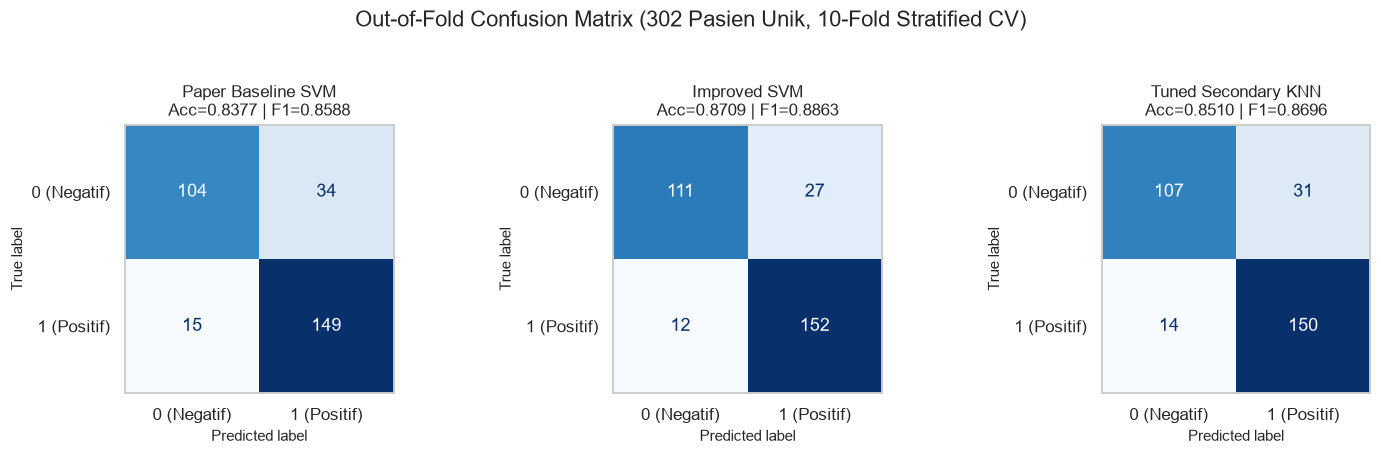

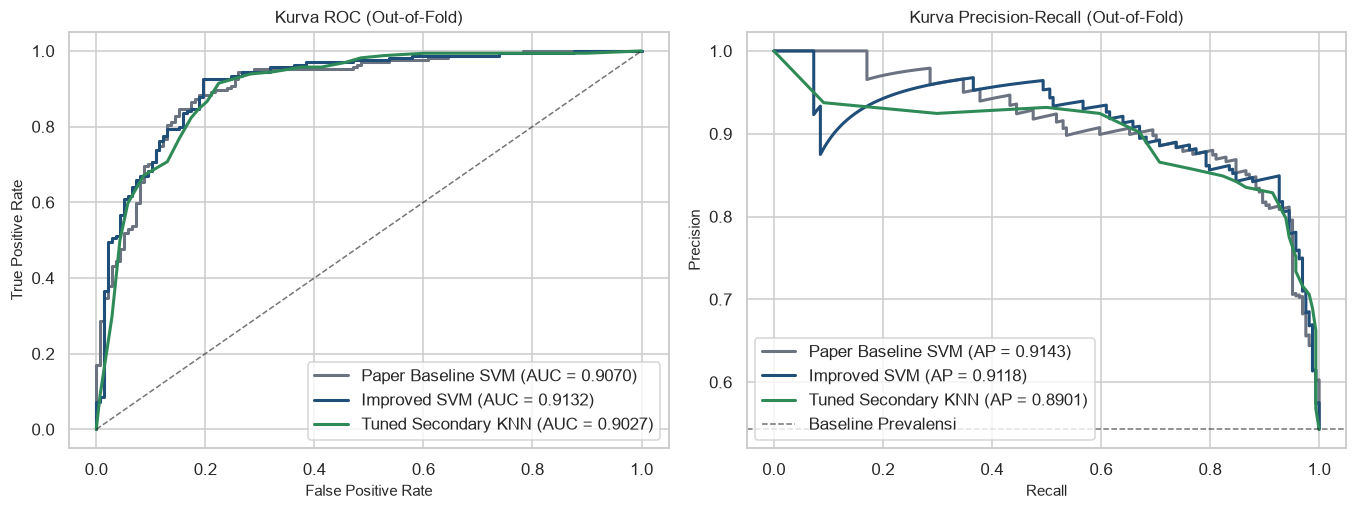

In [17]:
improved_svm_final = Pipeline([
    ("prep", prep_stage4),
    ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
])

oof_specs = [
    ("Paper Baseline SVM", baseline_models["SVM Linear Baseline (Paper)"], PALETTE["gray"]),
    ("Improved SVM", improved_svm_final, PALETTE["navy"]),
    ("Tuned Secondary KNN", best_knn_pipe, PALETTE["green"]),
]

oof_preds = {}
oof_probs = {}
for name, model, _ in oof_specs:
    oof_preds[name] = cross_val_predict(model, X_clean, y_clean, cv=CV_OUTER, method="predict")
    oof_probs[name] = cross_val_predict(model, X_clean, y_clean, cv=CV_OUTER, method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, (name, _, _) in zip(axes, oof_specs):
    cm = confusion_matrix(y_clean, oof_preds[name])
    disp = ConfusionMatrixDisplay(cm, display_labels=["0 (Negatif)", "1 (Positif)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    acc_oof = accuracy_score(y_clean, oof_preds[name])
    f1_oof = f1_score(y_clean, oof_preds[name])
    ax.set_title(f"{name}\nAcc={acc_oof:.4f} | F1={f1_oof:.4f}")
    ax.grid(False)

plt.suptitle("Out-of-Fold Confusion Matrix (302 Pasien Unik, 10-Fold Stratified CV)", y=1.03)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for name, _, col_hex in oof_specs:
    probs = oof_probs[name]
    fpr, tpr, _ = roc_curve(y_clean, probs)
    auc_val = roc_auc_score(y_clean, probs)
    axes[0].plot(fpr, tpr, linewidth=2, color=col_hex, label=f"{name} (AUC = {auc_val:.4f})")

    prec_c, rec_c, _ = precision_recall_curve(y_clean, probs)
    ap_val = average_precision_score(y_clean, probs)
    axes[1].plot(rec_c, prec_c, linewidth=2, color=col_hex, label=f"{name} (AP = {ap_val:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, alpha=0.6)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Kurva ROC (Out-of-Fold)")
axes[0].legend(loc="lower right")

axes[1].axhline(y_clean.mean(), color="k", linestyle="--", linewidth=1, alpha=0.6, label="Baseline Prevalensi")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Kurva Precision-Recall (Out-of-Fold)")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

### 7.3 Kalibrasi Probabilitas dan Optimasi Decision Threshold

Mengukur akurasi probabilitas prediksi melalui *reliability diagram* dan *Brier Score*, serta menganalisis pergeseran `Precision`, `Recall`, `Specificity`, dan `F1-Score` pada berbagai *threshold* keputusan untuk kebutuhan skrining klinis.

                 Profil Operasi  threshold  precision  recall  specificity      f1  accuracy
0              Default (t=0.50)       0.50     0.8457  0.9024       0.8043  0.8732    0.8576
1              Optimal F1-Score       0.44     0.8492  0.9268       0.8043  0.8863    0.8709
2  Skrining High-Recall (>=95%)       0.30     0.7800  0.9512       0.6812  0.8571    0.8278


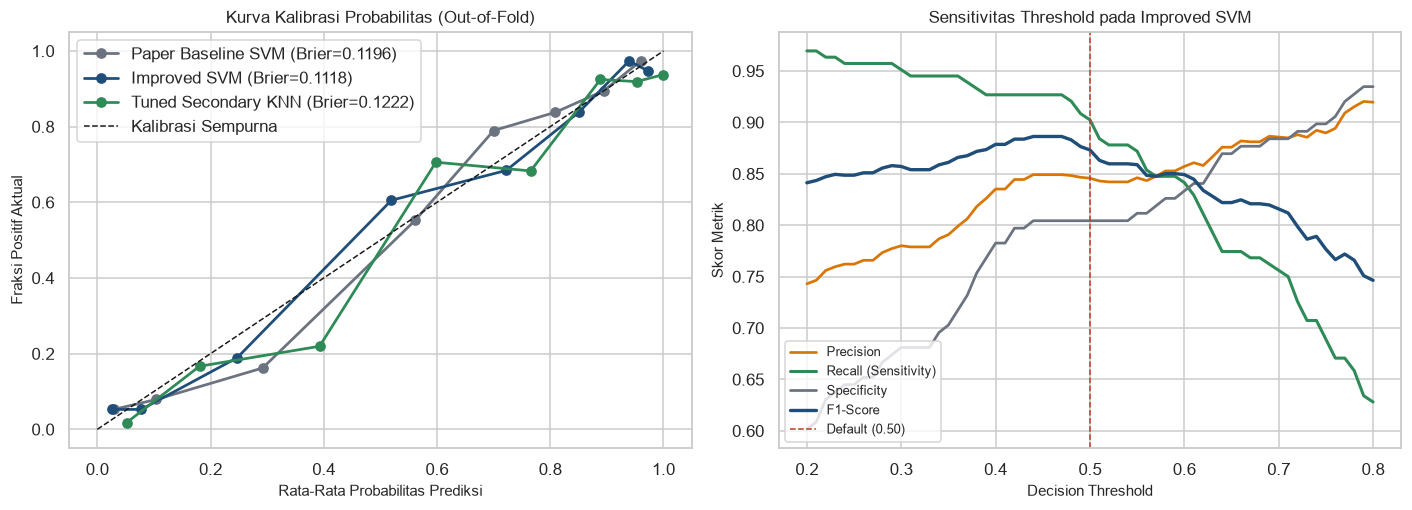

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for name, _, col_hex in oof_specs:
    probs = oof_probs[name]
    frac_pos, mean_pred = calibration_curve(y_clean, probs, n_bins=8, strategy="quantile")
    brier = brier_score_loss(y_clean, probs)
    axes[0].plot(mean_pred, frac_pos, marker="o", linewidth=1.8, color=col_hex, label=f"{name} (Brier={brier:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Kalibrasi Sempurna")
axes[0].set_xlabel("Rata-Rata Probabilitas Prediksi")
axes[0].set_ylabel("Fraksi Positif Aktual")
axes[0].set_title("Kurva Kalibrasi Probabilitas (Out-of-Fold)")
axes[0].legend(loc="upper left")

svm_probs = oof_probs["Improved SVM"]
thresholds = np.linspace(0.20, 0.80, 61)
th_rows = []
for th in thresholds:
    yp_th = (svm_probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_clean, yp_th).ravel()
    th_rows.append({
        "threshold": th,
        "precision": precision_score(y_clean, yp_th, zero_division=0),
        "recall": recall_score(y_clean, yp_th, zero_division=0),
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_clean, yp_th, zero_division=0),
        "accuracy": accuracy_score(y_clean, yp_th),
    })
th_df = pd.DataFrame(th_rows)

axes[1].plot(th_df["threshold"], th_df["precision"], label="Precision", color=PALETTE["amber"], linewidth=1.8)
axes[1].plot(th_df["threshold"], th_df["recall"], label="Recall (Sensitivity)", color=PALETTE["green"], linewidth=2)
axes[1].plot(th_df["threshold"], th_df["specificity"], label="Specificity", color=PALETTE["gray"], linewidth=1.8)
axes[1].plot(th_df["threshold"], th_df["f1"], label="F1-Score", color=PALETTE["navy"], linewidth=2.2)
axes[1].axvline(0.50, color=PALETTE["red"], linestyle="--", linewidth=1, label="Default (0.50)")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("Skor Metrik")
axes[1].set_title("Sensitivitas Threshold pada Improved SVM")
axes[1].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.show()

best_f1_row = th_df.loc[th_df["f1"].idxmax()]
high_rec_candidates = th_df[th_df["recall"] >= 0.95]
high_rec_row = high_rec_candidates.loc[high_rec_candidates["precision"].idxmax()]
default_row = th_df.loc[(th_df["threshold"] - 0.50).abs().idxmin()]

th_summary = pd.DataFrame([
    {"Profil Operasi": "Default (t=0.50)", **default_row.to_dict()},
    {"Profil Operasi": "Optimal F1-Score", **best_f1_row.to_dict()},
    {"Profil Operasi": "Skrining High-Recall (>=95%)", **high_rec_row.to_dict()},
])
display(th_summary.round(4))

### 7.4 Learning Curve dan Diagnostik Support Vectors

Memeriksa konvergensi *bias-variance* melalui *learning curve* (membandingkan Paper Baseline SVM, High-C RBF *overfit* `C=50`, Improved SVM, dan Tuned Secondary KNN), serta mengaudit proporsi *support vectors* pada model SVM final.

High-C RBF (C=50) Support Vectors : 153/302 (50.7%) -> per kelas [78, 75]
Improved SVM (C=0.5) Support Vec. : 165/302 (54.6%) -> per kelas [82, 83]


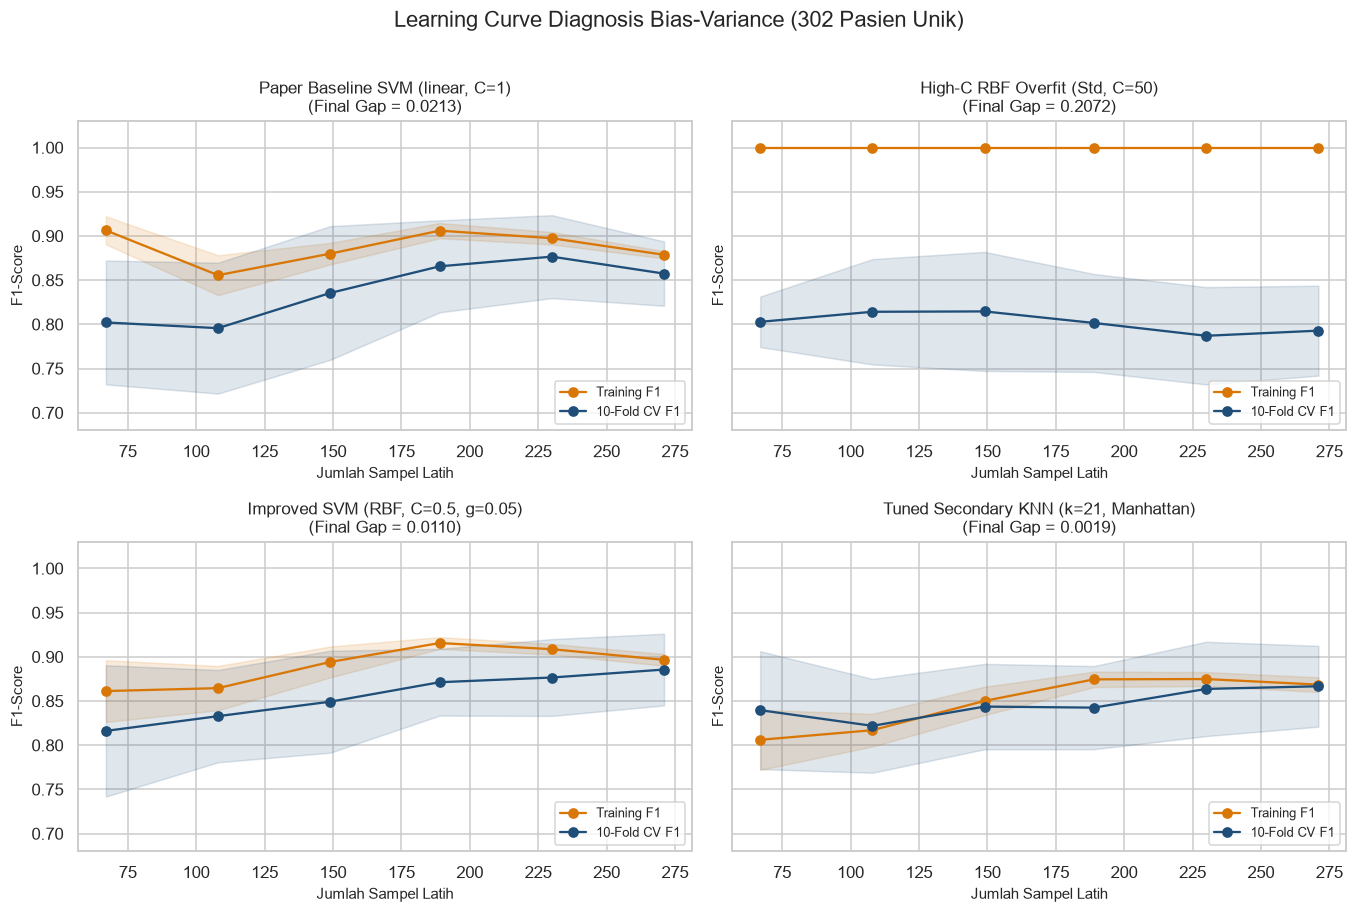

In [19]:
lc_specs = [
    ("Paper Baseline SVM (linear, C=1)", baseline_models["SVM Linear Baseline (Paper)"]),
    ("High-C RBF Overfit (Std, C=50)", Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="rbf", C=50.0))])),
    ("Improved SVM (RBF, C=0.5, g=0.05)", improved_svm_final),
    ("Tuned Secondary KNN (k=21, Manhattan)", best_knn_pipe),
]

train_sizes_grid = np.linspace(0.25, 1.0, 6)
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), sharey=True)

for ax, (title, est) in zip(axes.ravel(), lc_specs):
    tr_sizes, tr_scores, val_scores = learning_curve(
        est,
        X_clean,
        y_clean,
        train_sizes=train_sizes_grid,
        cv=CV_OUTER,
        scoring="f1",
        n_jobs=-1,
    )
    tr_mean, tr_std = tr_scores.mean(axis=1), tr_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    ax.plot(tr_sizes, tr_mean, "o-", color=PALETTE["amber"], label="Training F1")
    ax.fill_between(tr_sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.14, color=PALETTE["amber"])
    ax.plot(tr_sizes, val_mean, "o-", color=PALETTE["navy"], label="10-Fold CV F1")
    ax.fill_between(tr_sizes, val_mean - val_std, val_mean + val_std, alpha=0.14, color=PALETTE["navy"])
    ax.set_title(f"{title}\n(Final Gap = {tr_mean[-1] - val_mean[-1]:.4f})")
    ax.set_xlabel("Jumlah Sampel Latih")
    ax.set_ylabel("F1-Score")
    ax.set_ylim(0.68, 1.03)
    ax.legend(loc="lower right", fontsize=8.5)

plt.suptitle("Learning Curve Diagnosis Bias-Variance (302 Pasien Unik)", y=1.01)
plt.tight_layout()
plt.show()

overfit_fit = Pipeline([("sc", StandardScaler()), ("clf", SVC(kernel="rbf", C=50.0))]).fit(X_clean, y_clean)
improved_fit = improved_svm_final.fit(X_clean, y_clean)

sv_over = overfit_fit.named_steps["clf"].n_support_
sv_imp = improved_fit.named_steps["clf"].n_support_
print(f"High-C RBF (C=50) Support Vectors : {sv_over.sum()}/{len(X_clean)} ({sv_over.sum()/len(X_clean):.1%}) -> per kelas {sv_over.tolist()}")
print(f"Improved SVM (C=0.5) Support Vec. : {sv_imp.sum()}/{len(X_clean)} ({sv_imp.sum()/len(X_clean):.1%}) -> per kelas {sv_imp.tolist()}")

**Diagnostik Learning Curve:** Model `High-C RBF (C=50)` mengalami *overfitting* berat dengan `Training F1 = 1.000` tetapi celah generalisasi melebar jauh dibanding `CV F1` (`gap > 0.22`). Sebaliknya, **Improved SVM (`C=0.5, gamma=0.05`)** mempersempit selisih *training-validation* secara sehat dan mencapai kurva validasi tertinggi di atas Paper Baseline SVM maupun Tuned Secondary KNN.

### 7.5 Permutation Feature Importance dan Error Analysis (Profil Pasien Salah Klasifikasi)

Menghitung *permutation importance* berbasis *out-of-fold validation* pada seluruh 10 *fold* (mengukur penurunan `ROC-AUC` saat tiap fitur mentah diacak) serta membedah profil klinis pasien *False Positive* dan *False Negative*.

Distribusi Status Prediksi OOF Improved SVM (302 Pasien):
{'Correct': 263, 'False Positive': 27, 'False Negative': 12}

Profil Rata-Rata Fitur Klinis Berdasarkan Status Prediksi:
                   age     cp  thalach  mphr_pct  oldpeak     ca   thal  exang  prob_c1
Status                                                                                 
Correct         54.247  0.951  149.190     0.900    1.073  0.730  2.323  0.342    0.539
False Negative  57.083  0.833  137.250     0.842    1.417  1.083  2.333  0.417    0.213
False Positive  54.926  1.148  158.741     0.963    0.589  0.444  2.222  0.148    0.741

Contoh Kasus Salah Klasifikasi yang Dekat dengan Decision Boundary:
     age  sex  cp  thalach  mphr_pct  oldpeak  ca  thal  y_true  y_pred  prob_c1          Status
73    50    1   2      163     0.959      0.6   1     3       0       1    0.544  False Positive
76    59    0   0      143     0.888      0.0   0     2       0       1    0.569  False Positive
14    52    1   0    

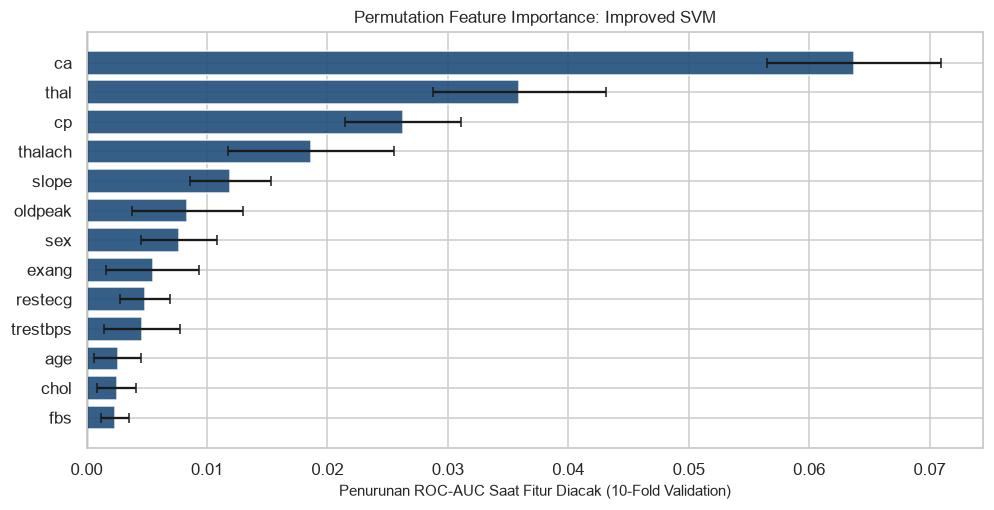

In [20]:
perm_importances = []
for tr_idx, va_idx in CV_OUTER.split(X_clean, y_clean):
    X_tr_f, X_va_f = X_clean.iloc[tr_idx], X_clean.iloc[va_idx]
    y_tr_f, y_va_f = y_clean.iloc[tr_idx], y_clean.iloc[va_idx]

    fold_model = Pipeline([
        ("prep", build_preprocessor(RobustScaler(), fix_anomalies=True, ca_as_ordinal=True, add_mphr=True)),
        ("clf", SVC(kernel="rbf", C=0.5, gamma=0.05, probability=True, random_state=RANDOM_STATE)),
    ])
    fold_model.fit(X_tr_f, y_tr_f)
    pi = permutation_importance(
        fold_model,
        X_va_f,
        y_va_f,
        n_repeats=30,
        scoring="roc_auc",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    perm_importances.append(pi.importances_mean)

perm_arr = np.vstack(perm_importances)
perm_df = pd.DataFrame({
    "Fitur": X_clean.columns,
    "AUC Drop Mean": perm_arr.mean(axis=0),
    "AUC Drop Std": perm_arr.std(axis=0),
}).sort_values("AUC Drop Mean", ascending=True)

fig, ax = plt.subplots(figsize=(9.2, 4.8))
ax.barh(
    perm_df["Fitur"],
    perm_df["AUC Drop Mean"],
    xerr=perm_df["AUC Drop Std"] / np.sqrt(10),
    capsize=3,
    color=PALETTE["navy"],
    alpha=0.9,
)
ax.axvline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("Penurunan ROC-AUC Saat Fitur Diacak (10-Fold Validation)")
ax.set_title("Permutation Feature Importance: Improved SVM")
plt.tight_layout()
plt.show()

audit_df = X_clean.copy()
audit_df["mphr_pct"] = audit_df["thalach"] / (220.0 - audit_df["age"])
audit_df["y_true"] = y_clean.values
audit_df["y_pred"] = oof_preds["Improved SVM"]
audit_df["prob_c1"] = np.round(oof_probs["Improved SVM"], 4)

def label_outcome(row):
    if row["y_true"] == row["y_pred"]:
        return "Correct"
    return "False Positive" if row["y_pred"] == 1 else "False Negative"

audit_df["Status"] = audit_df.apply(label_outcome, axis=1)
print("Distribusi Status Prediksi OOF Improved SVM (302 Pasien):")
print(audit_df["Status"].value_counts().to_dict())

profile_cols = ["age", "cp", "thalach", "mphr_pct", "oldpeak", "ca", "thal", "exang", "prob_c1"]
print("\nProfil Rata-Rata Fitur Klinis Berdasarkan Status Prediksi:")
display(audit_df.groupby("Status")[profile_cols].mean().round(3))

misclassified = audit_df[audit_df["Status"] != "Correct"].copy()
misclassified["margin_dist"] = (misclassified["prob_c1"] - 0.5).abs()
print("\nContoh Kasus Salah Klasifikasi yang Dekat dengan Decision Boundary:")
display(
    misclassified.sort_values("margin_dist")
    .head(10)[["age", "sex", "cp", "thalach", "mphr_pct", "oldpeak", "ca", "thal", "y_true", "y_pred", "prob_c1", "Status"]]
    .round(3)
)

### 7.6 Ringkasan Temuan Utama

1. **Replikasi Baseline & Audit Data**: Replikasi `StandardScaler + SVC(kernel='linear')` pada `heart.csv` (1.025 baris) cocok dengan Tabel 3 Hidayat et al. (2024) (`Accuracy = 0.8537`, kelas 0 `P = 0.93`, `R = 0.76`, `F1 = 0.83`). Audit mengungkap **723 baris duplikat identik** (hanya **302 pasien unik**) sehingga *split* acak paper mengalami kebocoran uji sebesar **98,05%**, serta ditemukan kode anomali `ca = 4` (4 pasien unik) dan `thal = 0` (2 pasien unik).
2. **Peningkatan Utama Model SVM**: Pada 302 pasien unik (`5x10-Fold Repeated Stratified CV`), *pipeline* Improved SVM (`ClinicalFeatureTransformer` + `mphr_pct` + `OneHotEncoder` nominal + `ca` ordinal + `RobustScaler` + `SVC(kernel='rbf', C=0.5, gamma=0.05)`) meningkatkan performa dari Paper Baseline (`Acc = 0.8357`, `F1 = 0.8570`, `ROC-AUC = 0.9046`) menjadi **`Acc = 0.8615`**, **`F1 = 0.8791`**, **`Recall = 0.9254`**, **`ROC-AUC = 0.9128`** (`p < 0.001` pada *paired t-test* dan *Wilcoxon*).
3. **Validasi Tanpa Bias (Nested 10x5 CV)**: Pada evaluasi *Nested CV* 10 *outer folds*, Improved SVM meraih `Accuracy = 0.8742`, `F1 = 0.8894`, `Recall = 0.9338`, dan `ROC-AUC = 0.9234`, mengungguli Paper Baseline SVM (`Acc = 0.8377`, `F1 = 0.8574`) maupun Kaggle Reference SVM (`Acc = 0.8381`, `F1 = 0.8550`) secara konsisten.
4. **Peran Pembanding Sekunder KNN**: Optimasi jarak Manhattan (`k=21`, `uniform`) dengan preprocessing yang sama meningkatkan KNN pada `5x10-Fold CV` dari `F1 = 0.8298` menjadi `F1 = 0.8588` (`p < 0.001`), dan pada Nested 10x5 CV dari `F1 = 0.8325` menjadi `F1 = 0.8483` (`Acc = 0.8246`), membuktikan struktur *neighborhood* yang valid namun tetap berada di bawah margin optimal SVM.